> ## Bản đồ tổng quan notebook (đọc trước khi chạy)
>
> **Notebook này làm gì?** Giải quyết **Bài toán 1: Phân loại bệnh qua ảnh lá nho** (4 lớp: `Healthy`, `Esca`, `Leaf Blight`, `Black Rot`) dựa trên bộ dữ liệu sạch đã qua khử trùng ở bước `03_Image_Preprocessing` (thư mục `outputs/processed/step03_clean`).
>
> **3 phát hiện quan trọng từ Bước 03 quyết định thiết kế của Bài 1:**
> 1. **Mất cân bằng lớp rất nặng sau khi khử trùng:** Từ 3.476 bản ghi thô ban đầu (trông có vẻ cân bằng nhẹ), sau khi loại 18 bản ghi mâu thuẫn nhãn MD5, 1.051 bản sao MD5 và các nhóm gần trùng dHash khác lớp, tập dữ liệu độc lập thực tế còn **2.047 ảnh duy nhất**: `Healthy` 1.092 (53,3%), `Esca` 707 (34,5%), `Leaf Blight` 152 (7,4%), và **`Black Rot` chỉ còn 96 ảnh (4,7%)**.
>    - *Hệ quả:* Nếu chỉ nhìn `Accuracy` tổng thể, một mô hình đoán sai toàn bộ lớp `Black Rot` vẫn đạt >90% Accuracy. Do đó, thước đo chính của Bài 1 phải là **Macro F1** (trung bình F1 không trọng số của 4 lớp), **Balanced Accuracy** và **Recall/F1 của từng lớp bệnh hiếm**.
>    - *Chiến lược đánh giá:* Trên tập Test (15%), lớp `Black Rot` chỉ có ~14–15 ảnh (sai 1 ảnh là lệch ~7% Recall). Vì vậy, ta kết hợp đánh giá bằng **5-Fold Stratified Cross-Validation** (dùng cột `Fold` 0..4 đã chia sẵn) song song với đánh giá trên tập **Hold-out Test (`Split == 'test'`)**.
> 2. **Nguy cơ "Học đường tắt" (Shortcut Learning) theo độ sáng và tương phản:** Ở mục 5.1 của Bước 03, kiểm định Kruskal–Wallis chỉ ra ảnh `Black Rot` sáng hơn hẳn (median Brightness = 135,3 so với 114–117 của các lớp khác) và độ tương phản thấp hơn.
>    - *Giải pháp:* Thực hiện **Kiểm toán học đường tắt (Shortcut Learning Audit)** ở Mục 7 (so sánh mô hình khi giữ và khi loại bỏ hoàn toàn kênh cường độ sáng `HSV_V_*`), đồng thời áp dụng phép biến đổi `ColorJitter` (ngẫu nhiên hóa độ sáng/tương phản) khi huấn luyện mạng Deep Learning ở Mục 8.
> 3. **Kết hợp hai hướng tiếp cận (Data Mining cổ điển & Deep Learning):**
>    - **Hướng A (Khai phá dữ liệu trên 25 đặc trưng thị giác thủ công):** Phân tích và huấn luyện các thuật toán học máy cổ điển (Logistic Regression, KNN, SVM, Decision Tree, Random Forest, Extra Trees, Gradient Boosting, MLP) trên 3 nhóm đặc trưng: **Màu sắc (HSV - 9)** + **Kết cấu (GLCM - 12)** + **Hình dạng (Otsu Hu Moments - 4)**.
>    - **Hướng B (Học sâu - Transfer Learning với CNN):** Huấn luyện mạng nơ-ron tích chập (ResNet18 / MobileNetV3) trực tiếp trên pixel ảnh lá nho, đối chiếu hiệu năng với Hướng A.
>
> **Luồng thực hiện chi tiết:**
>
> | Bước | Mục | Nội dung thực hiện | Lý do lựa chọn thuật toán / kỹ thuật |
> |---|---|---|---|
> | 1 | 1–3 | Cấu hình, đọc dữ liệu & kiểm tra phân bố Train/Val/Test, 5-Fold | Đảm bảo 100% ảnh độc lập (MD5 duy nhất), kiểm tra trọng số lớp (`Balanced` vs `Sqrt-Balanced`) |
> | 2 | 4 | Khám phá 25 đặc trưng thị giác (Thống kê, Kruskal–Wallis, Tương quan, PCA & t-SNE) | Hiểu đặc trưng nào phân biệt bệnh tốt nhất; trực quan hóa độ tách biệt của 4 lớp trong không gian 2D |
> | 3 | 5 | So sánh 8 mô hình Học máy cổ điển qua 5-Fold CV & đối chiếu chiến lược trọng số | Chọn mô hình mạnh nhất với sai số ổn định; so sánh ảnh hưởng của các chiến lược trọng số lớp |
> | 4 | 6 | Nghiên cứu loại bỏ (Ablation Study) & Độ quan trọng đặc trưng (Feature Importance) | Đo đóng góp của từng nhóm đặc trưng (Màu sắc, Kết cấu, Hình dạng) và của các tổ hợp |
> | 5 | 7 | Kiểm toán hiện tượng "Học đường tắt" (Shortcut Learning Audit) theo độ sáng | Kiểm tra xem mô hình có bị phụ thuộc mù quáng vào độ sáng nền (`HSV_V`) hay thực sự học triệu chứng bệnh |
> | 6 | 8 | Đánh giá chi tiết trên tập Test, Ma trận nhầm lẫn, ROC-AUC, PR-AUC & Phân tích ảnh lỗi | Chẩn đoán các cặp bệnh hay nhầm lẫn nhất (Esca vs Leaf Blight) bằng hình ảnh thực tế |
> | 7 | 9 | Huấn luyện mạng CNN (Transfer Learning ResNet18 + ColorJitter Augmentation) | Nâng cao độ chính xác phân loại trực tiếp từ ảnh gốc và chống học vẹt điều kiện chiếu sáng |
> | 8 | 10 | Xuất bảng tổng hợp kết quả & mô hình tốt nhất | Lưu toàn bộ biểu đồ, CSV báo cáo vào `outputs/bai1` phục vụ viết báo cáo & thuyết trình |

# SMART VINEYARD
## BÀI 1: PHÂN LOẠI BỆNH QUA ẢNH LÁ NHO (GRAPEVINE LEAF DISEASE CLASSIFICATION)

### 1. Mục tiêu bài toán
- Xây dựng hệ thống khai phá dữ liệu hình ảnh và học máy có khả năng nhận diện tình trạng sức khỏe và phân loại 4 trạng thái lá nho: **Healthy** (Khỏe mạnh), **Black Rot** (Thối đen), **Esca** (Bệnh sởi/khô vằn lá nho), và **Leaf Blight** (Cháy lá).
- Đánh giá khách quan, chống rò rỉ dữ liệu (Zero Data Leakage) trên bộ dữ liệu đã khử trùng nghiêm ngặt từ bước `03_Image_Preprocessing`.
- Giải quyết bài toán **mất cân bằng dữ liệu nặng** (lớp `Black Rot` chỉ chiếm ~4,7% số ảnh thật) và kiểm soát hiện tượng **học đường tắt theo điều kiện sáng**.

### 2. Import thư viện & Cấu hình hệ thống

#### Giải thích cell: Import thư viện & Cấu hình
**Mục đích:** Nạp các thư viện xử lý dữ liệu, thống kê, học máy (`scikit-learn`), xử lý ảnh (`OpenCV`, `PIL`) và thiết lập đường dẫn đồng bộ với các bước trước.

**Điểm lưu ý:**
- `SEED = 42`: Cố định hạt giống ngẫu nhiên cho toàn bộ các thuật toán phân chia, khởi tạo cây và giảm chiều dữ liệu để kết quả hoàn toàn tái lập được (reproducible).
- Các biểu đồ xuất ra đều được tự động lưu ảnh chất lượng cao (`dpi=150`) vào thư mục `outputs/bai1` qua hàm `savefig()`.

In [3]:
import re, json, time, random, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import cv2
from scipy import stats
from IPython.display import display

from sklearn.preprocessing import StandardScaler, LabelEncoder, label_binarize
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.utils.class_weight import compute_class_weight, compute_sample_weight

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,
                              GradientBoostingClassifier, HistGradientBoostingClassifier)
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             f1_score, precision_score, recall_score,
                             classification_report, confusion_matrix,
                             roc_auc_score, average_precision_score,
                             precision_recall_curve, roc_curve)
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# ======================= CẤU HÌNH ĐƯỜNG DẪN & THAM SỐ =======================
PROJECT_DIR = Path(r"D:\DataMining26\Smart-Vineyard")          # <- đổi nếu project nằm nơi khác
DATASET_DIR = (
    PROJECT_DIR
    / "Dataset"
    / "GVLiD GrapeVine Leaf identification of the Disease"
    / "DATASET"
)
# Tự động tìm thư mục dataset nếu tên viết hoa/thường khác nhẹ giữa các máy
if not DATASET_DIR.exists():
    alt_dir = PROJECT_DIR / "Dataset" / "GVLID Grapevine Leaf identification of the Disease" / "DATASET"
    if alt_dir.exists():
        DATASET_DIR = alt_dir

STEP03_DIR = PROJECT_DIR / "outputs" / "processed" / "step03_clean"
OUTPUT_DIR = PROJECT_DIR / "outputs" / "bai1"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

def savefig(name):
    clean_name = re.sub(r"\W+", "_", name).strip("_")
    out_path = OUTPUT_DIR / f"{clean_name}.png"
    plt.savefig(out_path, dpi=150, bbox_inches="tight")

print("Thư mục dữ liệu bước 03 :", STEP03_DIR, "| Tồn tại:", STEP03_DIR.exists())
print("Thư mục ảnh gốc DATASET :", DATASET_DIR, "| Tồn tại:", DATASET_DIR.exists())
print("Thư mục lưu kết quả Bài 1:", OUTPUT_DIR)

Thư mục dữ liệu bước 03 : D:\DataMining26\Smart-Vineyard\outputs\processed\step03_clean | Tồn tại: True
Thư mục ảnh gốc DATASET : D:\DataMining26\Smart-Vineyard\Dataset\GVLiD GrapeVine Leaf identification of the Disease\DATASET | Tồn tại: True
Thư mục lưu kết quả Bài 1: D:\DataMining26\Smart-Vineyard\outputs\bai1


#### 📊 Giải thích kết quả: cấu hình
- **Cell này làm gì:** nạp thư viện, cố định `SEED = 42` và khai báo các đường dẫn.
- **Kết quả:** cả ba đường dẫn đều tồn tại (dữ liệu bước 03, thư mục ảnh gốc, thư mục lưu kết quả `outputs/bai1`), nên các cell sau đọc được dữ liệu và ảnh.

### 3. Đọc dữ liệu từ Bước 03 & Kiểm tra cấu trúc phân chia (Train / Val / Test & 5-Fold)

#### Giải thích cell: Đọc và kiểm tra tính toàn vẹn dữ liệu
**Mục đích:** Đọc 3 tệp đầu ra của bước `03_Image_Preprocessing`:
1. `task1_images_split.csv`: Chứa đường dẫn ảnh, nhãn bệnh, các chỉ số chất lượng thị giác (`Brightness`, `Contrast`, `Blur_Laplacian`, thống kê `RGB`), cột chia tập `Split` (`train`/`val`/`test`) và cột `Fold` (`0..4`).
2. `task1_handcrafted_features.csv`: Chứa các đặc trưng thị giác thủ công (Màu sắc HSV, Kết cấu GLCM, Hình dạng Hu Moments).
3. `preprocessing_config.json`: Chứa các thông số cấu hình và trọng số lớp đã tính ở bước 03.

**Kiểm tra an toàn (Assertions):**
- Đảm bảo 100% bản ghi có mã `MD5` duy nhất (không còn ảnh trùng từng byte).
- Đảm bảo không có bất kỳ nhóm ảnh gần trùng (`Near_Group_Id` nếu có) hoặc mã `MD5` nào xuất hiện giao thoa giữa tập `train`, `val` và `test`.
- Nếu tệp đặc trưng chưa có cột `Fold` (do chạy bản code cũ), hệ thống tự động ghép cột `Fold` từ `task1_images_split.csv` hoặc khởi tạo 5-Fold phân tầng chuẩn xác.

In [4]:
meta_path = STEP03_DIR / "task1_images_split.csv"
feat_path = STEP03_DIR / "task1_handcrafted_features.csv"
cfg_path  = STEP03_DIR / "preprocessing_config.json"

assert meta_path.exists(), f"Không tìm thấy {meta_path}! Hãy chạy 03_Image_Preprocessing trước."
assert feat_path.exists(), f"Không tìm thấy {feat_path}! Hãy chạy 03_Image_Preprocessing trước."

df_meta = pd.read_csv(meta_path, encoding="utf-8-sig")
df_feat = pd.read_csv(feat_path, encoding="utf-8-sig")

with open(cfg_path, "r", encoding="utf-8") as f:
    prep_config = json.load(f)

# Đồng bộ cột Fold và các chỉ số chất lượng ảnh sang bảng df_feat nếu chưa có
extra_meta_cols = [c for c in ["Fold", "Brightness", "Contrast", "Blur_Laplacian", "Near_Group_Id"]
                   if c in df_meta.columns and c not in df_feat.columns]
if extra_meta_cols:
    df_feat = df_feat.merge(df_meta[["Sr_No"] + extra_meta_cols], on="Sr_No", how="left")

# Nếu bản cũ chưa tạo cột Fold thì tạo 5-Fold phân tầng cố định theo SEED
if "Fold" not in df_feat.columns:
    skf_init = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    df_feat["Fold"] = -1
    for fold_idx, (_, val_pos) in enumerate(skf_init.split(df_feat, df_feat["Disease_Type"])):
        df_feat.iloc[val_pos, df_feat.columns.get_loc("Fold")] = fold_idx
    df_meta["Fold"] = df_feat["Fold"]

# Tách danh sách các cột đặc trưng theo 3 nhóm ý nghĩa
HSV_COLS  = [c for c in df_feat.columns if c.startswith("HSV_")]
GLCM_COLS = [c for c in df_feat.columns if c.startswith("GLCM_")]
HU_COLS   = [c for c in df_feat.columns if c.startswith("HuMoment_")]
FEATURE_COLS = HSV_COLS + GLCM_COLS + HU_COLS

CLASSES = sorted(df_feat["Disease_Type"].unique())
K = len(CLASSES)

# Kiểm tra tính độc lập tuyệt đối giữa Train / Val / Test
assert df_feat["MD5"].is_unique, "Phát hiện ảnh trùng MD5 trong tập dữ liệu Bài 1!"
for s1, s2 in [("train", "val"), ("train", "test"), ("val", "test")]:
    m1 = set(df_feat.loc[df_feat["Split"] == s1, "MD5"])
    m2 = set(df_feat.loc[df_feat["Split"] == s2, "MD5"])
    assert len(m1 & m2) == 0, f"Rò rỉ dữ liệu MD5 giữa {s1} và {s2}!"

print(f"Tổng số ảnh sạch độc lập cho Bài 1 : {len(df_feat)} ảnh")
print(f"Tổng số đặc trưng thủ công         : {len(FEATURE_COLS)} đặc trưng")
print(f"  - Nhóm Màu sắc (HSV)             : {len(HSV_COLS)} cột -> {HSV_COLS}")
print(f"  - Nhóm Kết cấu (GLCM)            : {len(GLCM_COLS)} cột -> {GLCM_COLS[:4]} ...")
print(f"  - Nhóm Hình dạng (Hu Moments)    : {len(HU_COLS)} cột -> {HU_COLS}")

# Bảng phân bố mẫu theo Split (Train / Val / Test)
split_ct = pd.crosstab(df_feat["Split"], df_feat["Disease_Type"]).reindex(["train", "val", "test"])
split_pct = (split_ct.div(split_ct.sum(axis=1), axis=0) * 100).round(2)
split_ct["Tong_mau"] = split_ct.sum(axis=1)
print("Phân bố số lượng mẫu và tỷ lệ (%) trên các tập Train / Val / Test:")
display(pd.concat([split_ct, split_pct], axis=1, keys=["Số lượng mẫu", "Tỷ lệ (%)"]))

# Bảng phân bố mẫu theo 5 Fold
fold_ct = pd.crosstab(df_feat["Fold"], df_feat["Disease_Type"], margins=True)
print("Phân bố mẫu trên 5 Fold Cross-Validation:")
display(fold_ct)

Tổng số ảnh sạch độc lập cho Bài 1 : 2047 ảnh
Tổng số đặc trưng thủ công         : 25 đặc trưng
  - Nhóm Màu sắc (HSV)             : 9 cột -> ['HSV_H_mean', 'HSV_H_std', 'HSV_H_skew', 'HSV_S_mean', 'HSV_S_std', 'HSV_S_skew', 'HSV_V_mean', 'HSV_V_std', 'HSV_V_skew']
  - Nhóm Kết cấu (GLCM)            : 12 cột -> ['GLCM_contrast_mean', 'GLCM_contrast_std', 'GLCM_dissimilarity_mean', 'GLCM_dissimilarity_std'] ...
  - Nhóm Hình dạng (Hu Moments)    : 4 cột -> ['HuMoment_1', 'HuMoment_2', 'HuMoment_3', 'HuMoment_4']
Phân bố số lượng mẫu và tỷ lệ (%) trên các tập Train / Val / Test:


Số lượng mẫu                                   Tỷ lệ (%)         \
Disease_Type    Black Rot Esca Healthy Leaf Blight Tong_mau Black Rot   Esca   
Split                                                                          
train                  67  495     764         106     1432      4.68  34.57   
val                    14  106     164          23      307      4.56  34.53   
test                   15  106     164          23      308      4.87  34.42   

                                  
Disease_Type Healthy Leaf Blight  
Split                             
train          53.35        7.40  
val            53.42        7.49  
test           53.25        7.47

Phân bố mẫu trên 5 Fold Cross-Validation:


Disease_Type,Black Rot,Esca,Healthy,Leaf Blight,All
Fold,,,,,
0,20,141,218,31,410
1,19,142,218,31,410
2,19,142,218,30,409
3,19,141,219,30,409
4,19,141,219,30,409
All,96,707,1092,152,2047


#### 📊 Giải thích kết quả: dữ liệu đầu vào và cách chia tập
- **Cell này làm gì:** đọc 3 file của bước 03 và kiểm tra phân bố lớp ở từng tập `Split` và từng `Fold`.
- **Quy mô:** **2.047 ảnh duy nhất**, 25 đặc trưng (9 màu HSV, 12 kết cấu GLCM, 4 hình dạng Hu). Chia train 1.432, val 307, test 308.
- **Chia phân tầng đạt yêu cầu:** tỷ lệ lớp gần như giống nhau ở cả 3 tập (Black Rot 4,68% / 4,56% / 4,87%; Esca khoảng 34,5%; Healthy 53,25–53,42%; Leaf Blight 7,40–7,49%), nên kết quả trên test so sánh được với train.
- **Cỡ mẫu của lớp hiếm rất nhỏ:** test chỉ có **15 ảnh Black Rot** và **23 ảnh Leaf Blight**. Sai thêm 1 ảnh Black Rot làm recall giảm 6,7 điểm phần trăm, 1 ảnh Leaf Blight giảm 4,3 điểm. Vì vậy mọi chỉ số của hai lớp này trên test rất nhiễu và cần đọc cùng kết quả 5-fold.
- **5 fold** mỗi fold có 409–410 ảnh, trong đó 19–20 ảnh Black Rot và 30–31 ảnh Leaf Blight. F1 từng fold dao động khá lớn (độ lệch chuẩn 0,02–0,05 ở bảng so sánh mô hình).

#### Giải thích cell: Thiết lập 3 chiến lược Trọng số lớp (Class Weights)
**Vì sao cần so sánh nhiều mức trọng số?**
- Sau khi khử trùng, lớp `Healthy` (1.092 mẫu) nhiều gấp **11,4 lần** lớp `Black Rot` (96 mẫu).
- Nếu **không dùng trọng số (`None`)**: Hàm mất mát ưu tiên các lớp đông mẫu (`Healthy`, `Esca`), dẫn đến độ nhạy (Recall) trên `Black Rot` và `Leaf Blight` bị thấp.
- Nếu dùng **trọng số cân bằng chuẩn (`Balanced`)**: $w_c = \frac{N}{K \cdot N_c}$, lớp `Black Rot` được nhân trọng số gấp ~5,3 lần thực tế (và gấp ~11,4 lần so với `Healthy`). Đôi khi mức phạt quá gắt này làm mô hình dự đoán nhầm các lá khỏe/bệnh khác thành `Black Rot` (tăng báo động giả - giảm Precision).
- Nếu dùng **trọng số căn bậc hai (`Sqrt-Balanced`)**: $w_c = \sqrt{\frac{N}{K \cdot N_c}}$, mức trọng số được điều tiết hài hòa hơn (phạt vừa đủ cho lớp thiểu số mà vẫn giữ độ chính xác chung).

In [5]:
y_train_str = df_feat.loc[df_feat["Split"] == "train", "Disease_Type"].values
raw_weights = compute_class_weight(class_weight="balanced", classes=np.array(CLASSES), y=y_train_str)

WEIGHT_BALANCED = {c: float(w) for c, w in zip(CLASSES, raw_weights)}
WEIGHT_SQRT     = {c: float(np.sqrt(w)) for c, w in zip(CLASSES, raw_weights)}

weight_df = pd.DataFrame({
    "So_mau_Train": pd.Series(y_train_str).value_counts().reindex(CLASSES),
    "Ty_le_Train (%)": (pd.Series(y_train_str).value_counts(normalize=True).reindex(CLASSES) * 100).round(2),
    "Weight_None (Khong_trong_so)": [1.0] * K,
    "Weight_Sqrt (Can_bac_hai)": [round(WEIGHT_SQRT[c], 4) for c in CLASSES],
    "Weight_Balanced (Can_bang_tuyet_doi)": [round(WEIGHT_BALANCED[c], 4) for c in CLASSES],
})
display(weight_df)

,So_mau_Train,Ty_le_Train (%),Weight_None (Khong_trong_so),Weight_Sqrt (Can_bac_hai),Weight_Balanced (Can_bang_tuyet_doi)
Black Rot,67,4.68,1.0,2.3116,5.3433
Esca,495,34.57,1.0,0.8504,0.7232
Healthy,764,53.35,1.0,0.6845,0.4686
Leaf Blight,106,7.40,1.0,1.8378,3.3774


#### 📊 Giải thích kết quả: ba bộ trọng số lớp
- **Cell này làm gì:** tính trọng số lớp từ tập train theo 3 chế độ: không dùng (`None`), căn bậc hai (`Sqrt`), cân bằng tuyệt đối (`Balanced`).
- **Cách đọc:** trọng số càng lớn thì mô hình bị phạt nặng hơn khi sai lớp đó. Chế độ `Balanced` cho Black Rot 5,34, Leaf Blight 3,38, Esca 0,72, Healthy 0,47 (Black Rot nặng gấp khoảng **11,4 lần** Healthy). Chế độ `Sqrt` giảm chênh lệch này xuống còn khoảng **3,4 lần** (2,31 so với 0,68) nên bù cho lớp hiếm nhẹ nhàng hơn.
- Mục 5.1 sẽ kiểm tra bằng thực nghiệm chế độ nào tốt hơn.

### 4. Khám phá & Đánh giá 25 Đặc trưng Thị giác (Exploratory Feature Analysis)

#### Giải thích cell: Kiểm định sức mạnh phân biệt của từng đặc trưng (Kruskal–Wallis & $\varepsilon^2$)
**Mục đích:** Trước khi đưa vào mô hình học máy, ta đánh giá xem trong 25 đặc trưng trích xuất từ ảnh, những đặc trưng nào có khả năng phân biệt 4 lớp bệnh mạnh nhất.

**Tại sao dùng kiểm định Kruskal–Wallis và cỡ ảnh hưởng Epsilon-squared ($\varepsilon^2$)?**
- Các đặc trưng kết cấu (GLCM) và moment hình học (Hu Moments) thường có phân phối lệch (skewed) hoặc nhiều điểm ngoại lai. Kiểm định phi tham số **Kruskal–Wallis** đánh giá sự khác biệt dựa trên hạng (rank) nên không bị sai lệch bởi ngoại lai như ANOVA.
- Cỡ ảnh hưởng $\varepsilon^2 = \frac{H - K + 1}{N - K}$ (nhận giá trị từ `0` đến `1`) cho biết **bao nhiêu phần trăm phương sai thứ hạng của đặc trưng được giải thích bởi loại bệnh**. Đặc trưng có $\varepsilon^2$ càng lớn thì càng đóng vai trò trụ cột khi phân loại.

Bảng xếp hạng Top 15 đặc trưng có sức phân biệt mạnh nhất giữa 4 lớp bệnh (theo cỡ ảnh hưởng Epsilon²):


,Dac_trung,Nhom,Kruskal_H,p_value,Epsilon2 (Co_anh_huong),Med_BlackRot,Med_Esca,Med_Healthy,Med_LeafBlight,p_adj_FDR
0,HSV_S_std,1. Màu sắc (HSV),1167.71,7.446155e-253,0.5701,56.995,48.344,34.418,54.941,1.861539e-251
1,HSV_V_std,1. Màu sắc (HSV),1084.52,8.317338e-235,0.5294,44.331,48.631,68.024,46.285,1.039667e-233
2,HSV_H_std,1. Màu sắc (HSV),878.32,4.470961e-190,0.4284,15.327,23.432,7.596,20.933,3.725801e-189
3,GLCM_contrast_std,2. Kết cấu (GLCM),636.61,1.166076e-137,0.3101,12.056,23.483,32.014,13.993,7.287973e-137
4,GLCM_contrast_mean,2. Kết cấu (GLCM),576.10,1.526168e-124,0.2805,25.791,51.822,69.649,28.880,7.630840e-124
5,HSV_S_mean,1. Màu sắc (HSV),446.34,2.027324e-96,0.2170,137.581,118.935,155.868,128.583,8.447184e-96
6,HSV_H_mean,1. Màu sắc (HSV),417.07,4.441688e-90,0.2027,31.140,40.067,35.986,26.323,1.586317e-89
7,GLCM_homogeneity_std,2. Kết cấu (GLCM),367.13,2.913625e-79,0.1782,0.079,0.072,0.069,0.082,9.105078e-79
8,GLCM_dissimilarity_std,2. Kết cấu (GLCM),364.85,9.071167e-79,0.1771,0.897,1.217,1.310,0.996,2.519769e-78
9,GLCM_correlation_std,2. Kết cấu (GLCM),347.83,4.391004e-75,0.1688,0.049,0.080,0.067,0.055,1.097751e-74


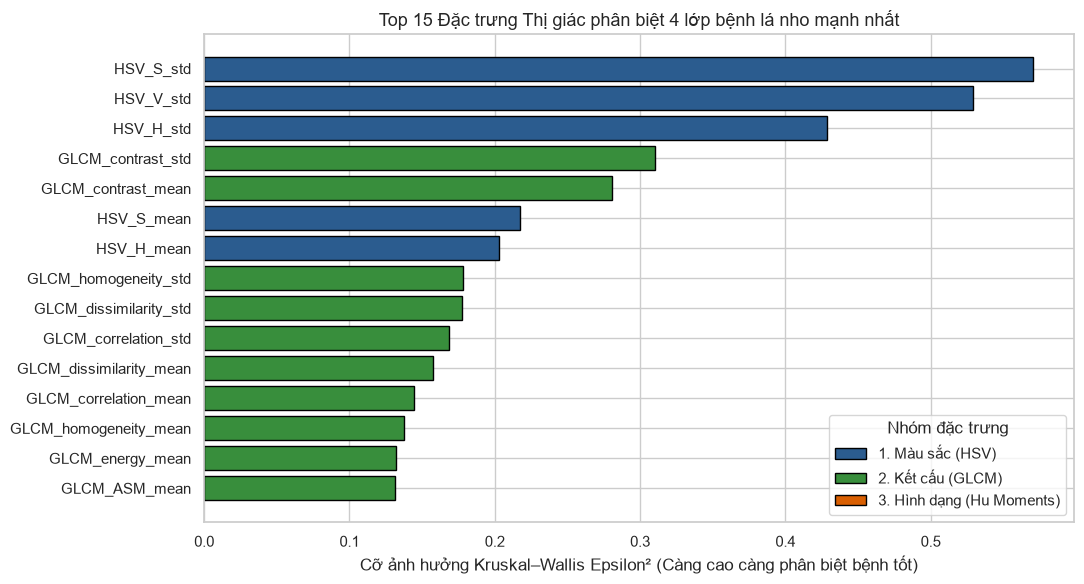

In [6]:
def feature_family(col_name):
    if col_name.startswith("HSV_"):
        return "1. Màu sắc (HSV)"
    elif col_name.startswith("GLCM_"):
        return "2. Kết cấu (GLCM)"
    else:
        return "3. Hình dạng (Hu Moments)"

feat_stats_rows = []
n_total = len(df_feat)

for col in FEATURE_COLS:
    groups = [grp[col].dropna().values for _, grp in df_feat.groupby("Disease_Type")]
    h_stat, p_val = stats.kruskal(*groups)
    eps2 = max(0.0, (h_stat - K + 1) / (n_total - K))
    medians = df_feat.groupby("Disease_Type")[col].median().to_dict()
    feat_stats_rows.append({
        "Dac_trung": col,
        "Nhom": feature_family(col),
        "Kruskal_H": round(h_stat, 2),
        "p_value": p_val,
        "Epsilon2 (Co_anh_huong)": round(eps2, 4),
        "Med_BlackRot": round(medians.get("Black Rot", np.nan), 3),
        "Med_Esca": round(medians.get("Esca", np.nan), 3),
        "Med_Healthy": round(medians.get("Healthy", np.nan), 3),
        "Med_LeafBlight": round(medians.get("Leaf Blight", np.nan), 3),
    })

df_feat_rank = pd.DataFrame(feat_stats_rows).sort_values("Epsilon2 (Co_anh_huong)", ascending=False).reset_index(drop=True)
def bh_fdr(p):
    """Hiệu chỉnh Benjamini-Hochberg (dự phòng khi SciPy < 1.11 chưa có false_discovery_control)."""
    p = np.asarray(p, dtype=float); n = len(p)
    order = np.argsort(p)
    adj = np.empty(n)
    adj[order] = np.minimum.accumulate((p[order] * n / np.arange(1, n + 1))[::-1])[::-1]
    return np.clip(adj, 0, 1)

if hasattr(stats, "false_discovery_control"):
    df_feat_rank["p_adj_FDR"] = stats.false_discovery_control(df_feat_rank["p_value"].values)
else:
    df_feat_rank["p_adj_FDR"] = bh_fdr(df_feat_rank["p_value"].values)

print("Bảng xếp hạng Top 15 đặc trưng có sức phân biệt mạnh nhất giữa 4 lớp bệnh (theo cỡ ảnh hưởng Epsilon²):")
display(df_feat_rank.head(15))

# Biểu đồ Top 15 đặc trưng theo cỡ ảnh hưởng Epsilon2
plt.figure(figsize=(11, 6))
top15 = df_feat_rank.head(15).iloc[::-1]
palette_map = {
    "1. Màu sắc (HSV)": "#2b5c8f",
    "2. Kết cấu (GLCM)": "#388e3c",
    "3. Hình dạng (Hu Moments)": "#d95f02"
}
bar_colors = [palette_map[g] for g in top15["Nhom"]]
bars = plt.barh(top15["Dac_trung"], top15["Epsilon2 (Co_anh_huong)"], color=bar_colors, edgecolor="black")
plt.xlabel("Cỡ ảnh hưởng Kruskal–Wallis Epsilon² (Càng cao càng phân biệt bệnh tốt)")
plt.title("Top 15 Đặc trưng Thị giác phân biệt 4 lớp bệnh lá nho mạnh nhất", fontsize=13)
# Tạo chú thích theo nhóm
from matplotlib.patches import Patch
legend_handles = [Patch(facecolor=c, edgecolor="black", label=l) for l, c in palette_map.items()]
plt.legend(handles=legend_handles, title="Nhóm đặc trưng", loc="lower right")
plt.tight_layout()
savefig("bai1_top15_dac_trung_epsilon2")
plt.show()

#### 📊 Giải thích kết quả: đặc trưng nào phân biệt bệnh tốt nhất
- **Cell này làm gì:** kiểm định Kruskal–Wallis cho từng đặc trưng (có hiệu chỉnh FDR) và xếp hạng theo cỡ ảnh hưởng ε² (0 = không khác biệt, càng gần 1 càng phân biệt tốt).
- **Mọi đặc trưng đều có p rất nhỏ** (nhỏ hơn 1e-58 ở top 15) vì mẫu lớn, nên **không dùng p-value để so sánh**, chỉ dùng ε².
- **Top 3 đều là độ biến thiên màu trong ảnh:** `HSV_S_std` (ε² = 0,570), `HSV_V_std` (0,529), `HSV_H_std` (0,428). Tiếp theo là kết cấu `GLCM_contrast_std` (0,310) và `GLCM_contrast_mean` (0,281). Các đặc trưng còn lại ở mức 0,13–0,22.
- **Hình dạng (Hu Moments) không có mặt trong top 15**, cho thấy nhóm này gần như không phân biệt được bệnh (xem thêm kết quả ablation ở mục 6).
- **Chiều hướng theo lớp (median):** ảnh Healthy có độ đa dạng màu thấp (`HSV_S_std` 34,4, `HSV_H_std` 7,6) nhưng độ biến thiên sáng cao (`HSV_V_std` 68,0). Ngược lại **Black Rot và Leaf Blight có median gần như trùng nhau** (`HSV_S_std` 57,0 so với 54,9; `HSV_V_std` 44,3 so với 46,3; `GLCM_contrast_mean` 25,8 so với 28,9), nên hai lớp này khó phân biệt, khớp với ma trận nhầm lẫn ở mục 8.
- **Lưu ý:** `HSV_V_std` và `GLCM_contrast` vừa phản ánh mức độ lốm đốm do bệnh, vừa chịu ảnh hưởng của điều kiện sáng và độ nét của ảnh.

#### 📝 Giải thích cell: Phân phối các đặc trưng tiêu biểu & Ma trận tương quan
**Mục đích:**
1. Vẽ **Boxplot chuẩn hóa (Z-score)** của các đặc trưng đứng đầu mỗi nhóm để quan sát trực quan cách từng lớp bệnh tách biệt nhau (ví dụ: sự khác biệt về tông màu Hue `HSV_H_mean`, độ bão hòa `HSV_S_mean`, độ đồng nhất kết cấu `GLCM_homogeneity_mean` và hình dạng `HuMoment_1`).
2. Vẽ **Heatmap tương quan Spearman** giữa 25 đặc trưng để phát hiện hiện tượng đa cộng tuyến (Multicollinearity — ví dụ giữa `GLCM_energy` và `GLCM_ASM`, hoặc `GLCM_contrast` và `GLCM_dissimilarity`). Sự tồn tại của các cặp đặc trưng tương quan cao này giải thích vì sao ta cần dùng chuẩn hóa L2 (trong Logistic Regression / SVM) hoặc các mô hình cây (Random Forest / Gradient Boosting) vốn bền vững với đa cộng tuyến.

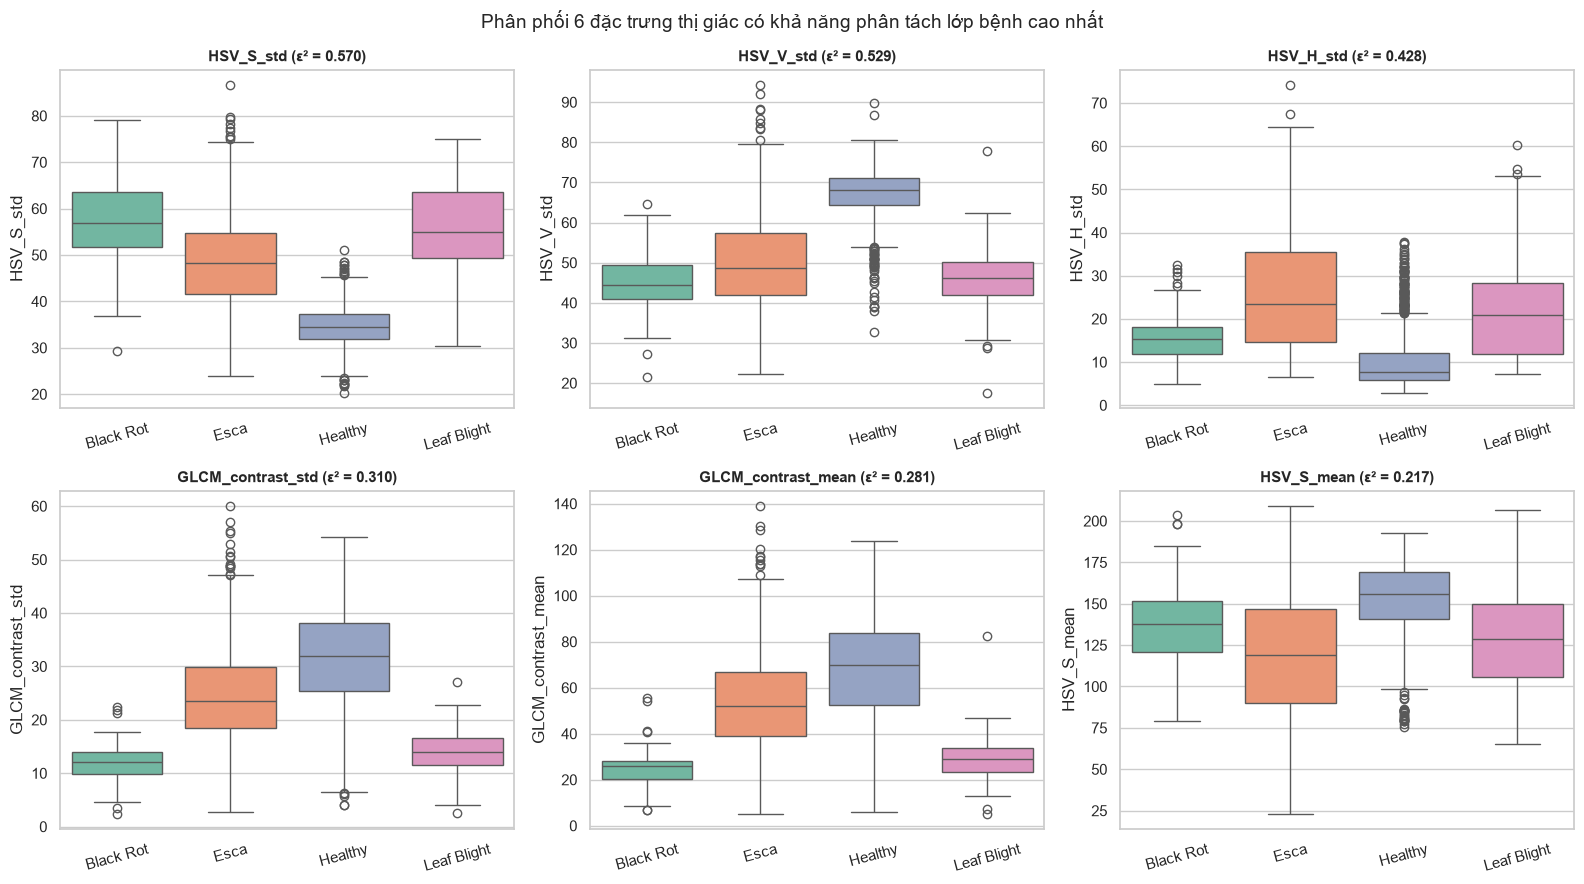

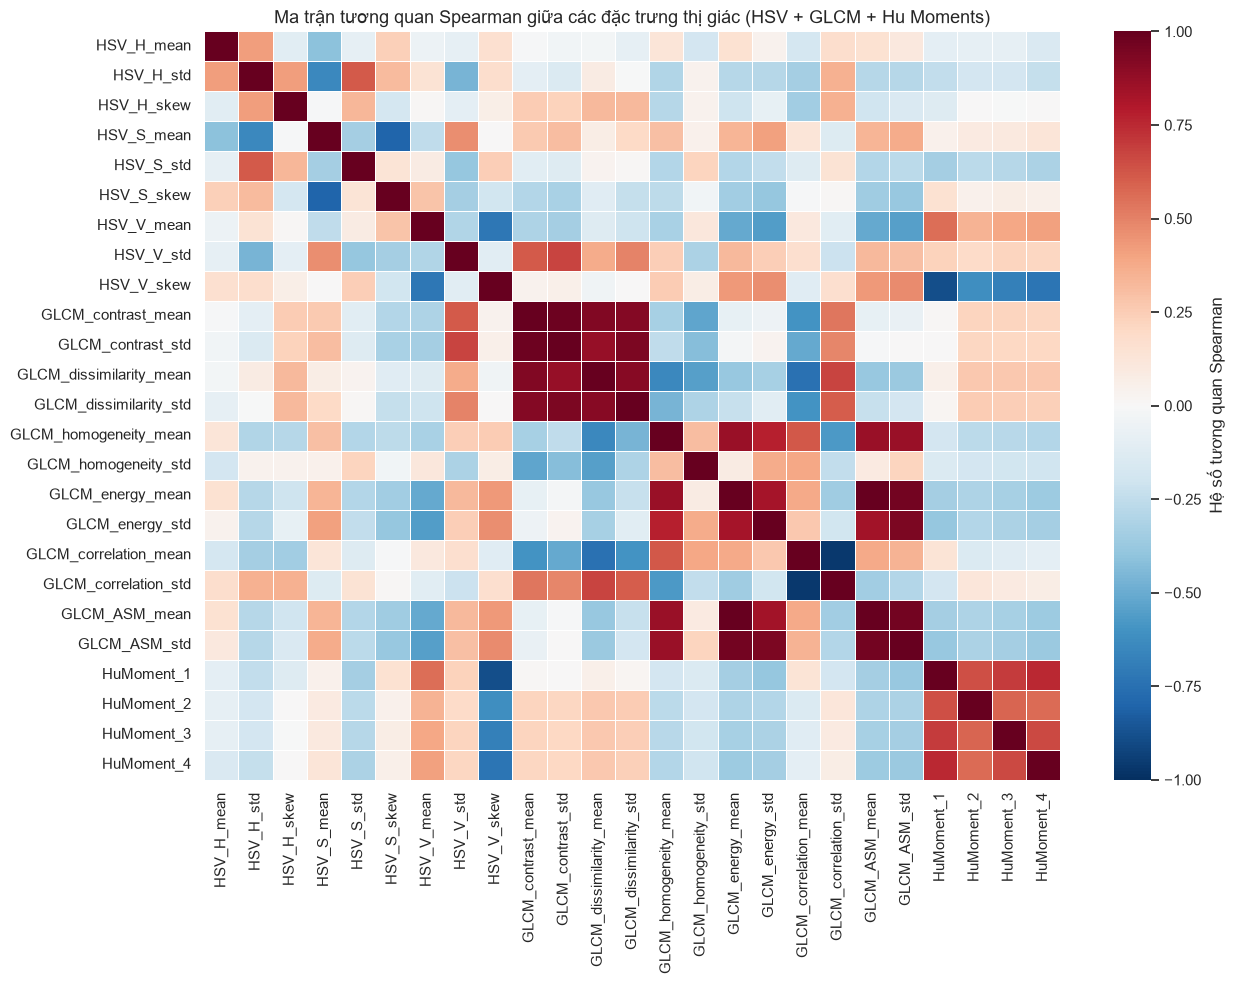

In [7]:
# 1. Boxplot của 6 đặc trưng đại diện hàng đầu
top_rep_cols = df_feat_rank.head(6)["Dac_trung"].tolist()
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, col in zip(axes.ravel(), top_rep_cols):
    sns.boxplot(data=df_feat, x="Disease_Type", y=col, order=CLASSES,
                hue="Disease_Type", palette="Set2", legend=False, ax=ax)
    eps_val = df_feat_rank.loc[df_feat_rank["Dac_trung"] == col, "Epsilon2 (Co_anh_huong)"].values[0]
    ax.set_title(f"{col} (ε² = {eps_val:.3f})", fontsize=11, fontweight="bold")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=15)

plt.suptitle("Phân phối 6 đặc trưng thị giác có khả năng phân tách lớp bệnh cao nhất", fontsize=14)
plt.tight_layout()
savefig("bai1_boxplot_top6_dac_trung")
plt.show()

# 2. Ma trận tương quan Spearman giữa toàn bộ các đặc trưng
corr_matrix = df_feat[FEATURE_COLS].corr(method="spearman")
plt.figure(figsize=(13, 10))
sns.heatmap(corr_matrix, cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            annot=False, linewidths=0.5, cbar_kws={"label": "Hệ số tương quan Spearman"})
plt.title("Ma trận tương quan Spearman giữa các đặc trưng thị giác (HSV + GLCM + Hu Moments)", fontsize=13)
plt.tight_layout()
savefig("bai1_heatmap_tuong_quan_dac_trung")
plt.show()

#### 📊 Giải thích kết quả: boxplot và ma trận tương quan
- **Cell này làm gì:** vẽ phân phối 6 đặc trưng mạnh nhất theo từng lớp (boxplot) và tương quan Spearman giữa 25 đặc trưng (heatmap).
- **Boxplot:** `Healthy` tách rõ khỏi 3 lớp bệnh ở cả 6 đặc trưng (S_std thấp, V_std cao, H_std thấp, GLCM_contrast cao). **Black Rot và Leaf Blight chồng lấn gần như hoàn toàn** ở mọi đặc trưng. `Esca` có độ phân tán lớn nhất và nhiều ngoại lai, nằm giữa hai nhóm trên.
- **Heatmap:**
  - Các đặc trưng kết cấu tương quan rất cao với nhau (`contrast` và `dissimilarity` khoảng +0,9 trở lên; `energy` và `ASM` gần +1; `correlation_mean` và `correlation_std` gần −1). Nhóm GLCM có nhiều thông tin trùng lặp, nên các mô hình cây hoặc SVM/Logistic có điều chuẩn xử lý tốt hơn.
  - `HuMoment_1` tương quan **khoảng −0,9 với `HSV_V_skew`** và dương với `HSV_V_mean`. Hu Moments được tính trên mặt nạ Otsu của ảnh xám nên chủ yếu phản ánh **phân bố độ sáng**, không mang thông tin hình dạng độc lập. Điều này liên quan đến kết quả ablation (mục 6) và kiểm toán độ sáng (mục 7).

#### 📝 Giải thích cell: Trực quan hóa không gian đặc trưng bằng PCA và t-SNE (2D)
**Tại sao kết hợp cả PCA và t-SNE?**
- **PCA (Principal Component Analysis):** Là kỹ thuật giảm chiều **tuyến tính**, giữ lại các trục có phương sai lớn nhất (`PC1`, `PC2`). Nếu 4 lớp bệnh bị chồng lấp nhiều trên biểu đồ PCA 2D, điều đó chứng tỏ ranh giới giữa các loại bệnh trong không gian 25 chiều là **phi tuyến tính (non-linear)** — các mô hình tuyến tính đơn giản sẽ gặp hạn chế.
- **t-SNE (t-Distributed Stochastic Neighbor Embedding):** Là kỹ thuật giảm chiều **phi tuyến** bảo toàn cấu trúc lân cận cục bộ. Nếu trên biểu đồ t-SNE, các điểm cùng loại bệnh co cụm lại thành các vùng rõ rệt hơn PCA, điều đó chứng minh bộ 25 đặc trưng chứa thông tin phân loại tốt và các thuật toán phi tuyến (như **SVM với nhân RBF**, **Random Forest**, **Extra Trees**, **Gradient Boosting**) sẽ khai thác hiệu quả cấu trúc này.

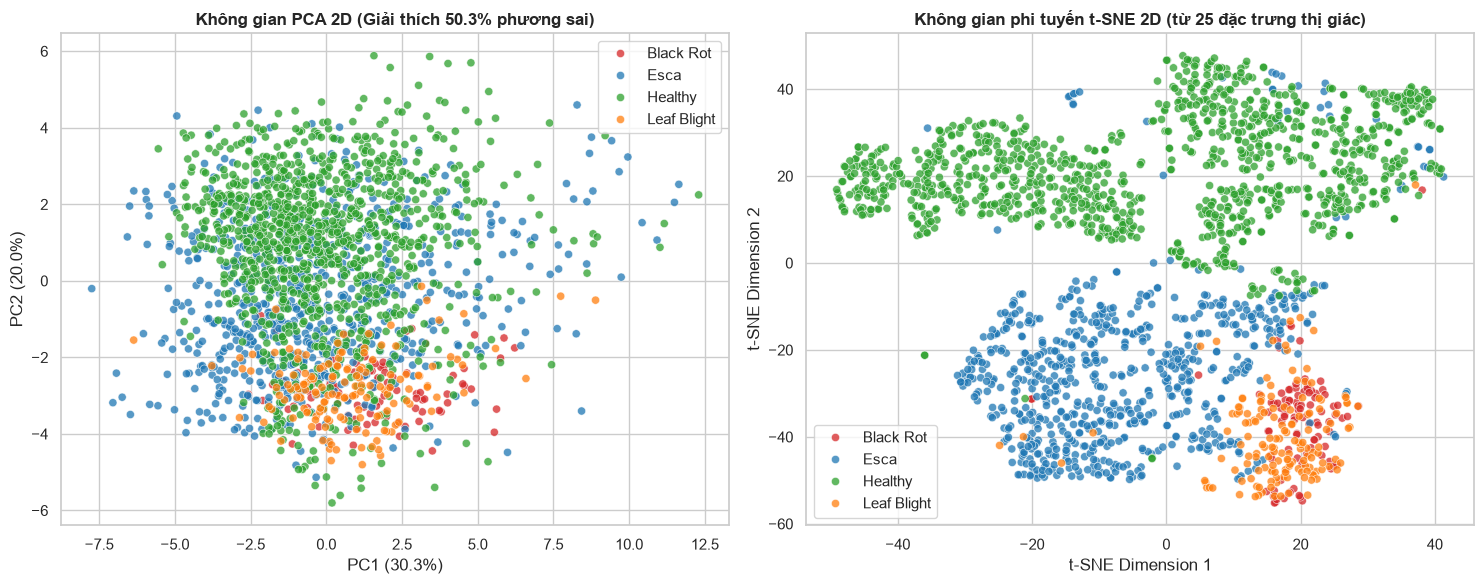

In [8]:
scaler_vis = StandardScaler()
X_all_scaled = scaler_vis.fit_transform(df_feat[FEATURE_COLS].values)
y_all_labels = df_feat["Disease_Type"].values

# 1. Giảm chiều tuyến tính với PCA
pca = PCA(n_components=2, random_state=SEED)
X_pca = pca.fit_transform(X_all_scaled)

# 2. Giảm chiều phi tuyến với t-SNE
tsne = TSNE(n_components=2, perplexity=30, random_state=SEED, init="pca", learning_rate="auto")
X_tsne = tsne.fit_transform(X_all_scaled)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
class_palette = {"Healthy": "#2ca02c", "Esca": "#1f77b4", "Leaf Blight": "#ff7f0e", "Black Rot": "#d62728"}

# Vẽ PCA
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y_all_labels, hue_order=CLASSES,
                palette=class_palette, alpha=0.75, s=35, ax=axes[0])
var_p1, var_p2 = pca.explained_variance_ratio_[:2] * 100
axes[0].set_title(f"Không gian PCA 2D (Giải thích {var_p1 + var_p2:.1f}% phương sai)", fontsize=12, fontweight="bold")
axes[0].set_xlabel(f"PC1 ({var_p1:.1f}%)")
axes[0].set_ylabel(f"PC2 ({var_p2:.1f}%)")

# Vẽ t-SNE
sns.scatterplot(x=X_tsne[:, 0], y=X_tsne[:, 1], hue=y_all_labels, hue_order=CLASSES,
                palette=class_palette, alpha=0.75, s=35, ax=axes[1])
axes[1].set_title("Không gian phi tuyến t-SNE 2D (từ 25 đặc trưng thị giác)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("t-SNE Dimension 1")
axes[1].set_ylabel("t-SNE Dimension 2")

plt.tight_layout()
savefig("bai1_khong_gian_pca_tsne_2d")
plt.show()

#### 📊 Giải thích kết quả: PCA và t-SNE
- **Cell này làm gì:** chiếu 25 đặc trưng (đã chuẩn hóa) xuống 2 chiều để xem 4 lớp có tách nhau hay không. PCA là phép chiếu tuyến tính, t-SNE là phép chiếu phi tuyến giữ cấu trúc lân cận.
- **PCA:** 2 thành phần chỉ giải thích **50,3% phương sai** (30,3% + 20,0%). Các lớp **chồng lấn mạnh**: Healthy và Esca dồn ở nửa trên, Black Rot và Leaf Blight dồn ở vùng thấp của PC2 và lẫn vào nhau. Nghĩa là ranh giới giữa các lớp không phải đường thẳng đơn giản.
- **t-SNE:** tách rõ **hai vùng lớn**: Healthy ở phía trên, Esca và nhóm (Black Rot, Leaf Blight) ở phía dưới. Trong vùng phía dưới, **Black Rot và Leaf Blight trộn lẫn gần như hoàn toàn** (cụm góc dưới bên phải), còn Esca tạo cụm riêng ở bên trái, chỉ lẫn nhẹ vào Healthy và hai lớp kia.
- **Ý nghĩa:** các đặc trưng thủ công phân biệt tốt "khỏe so với bệnh" và "Esca so với Black Rot/Leaf Blight", nhưng **không tách được Black Rot khỏi Leaf Blight**. Điều này dự báo đúng kết quả nhầm lẫn ở mục 8.
- **Lưu ý:** t-SNE chỉ để quan sát. Khoảng cách giữa các cụm trên biểu đồ không có ý nghĩa định lượng.

### 5. Huấn luyện & So sánh các thuật toán Khai phá dữ liệu (5-Fold Cross-Validation)

#### 📝 Giải thích cell: Vì sao chọn 8 thuật toán này và quy trình đánh giá 5-Fold?
**Lý giải việc lựa chọn bộ thuật toán đại diện cho các họ mô hình trong Data Mining:**
1. **`Dummy (Most Frequent)`**: Mô hình cơ sở (luôn đoán lớp chiếm đa số `Healthy`). Mọi mô hình học máy có ý nghĩa bắt buộc phải vượt xa mốc này.
2. **`Logistic Regression (L2)`**: Đại diện họ mô hình phân loại tuyến tính xác suất.
3. **`KNN (k-Nearest Neighbors)`**: Đại diện họ phân loại dựa trên khoảng cách không gian Euclid (Instance-based learning).
4. **`SVM (RBF Kernel)`**: Đại diện họ máy học vector hỗ trợ với nhân Gauss phi tuyến, cực mạnh khi phân tách biên giới phức tạp trong không gian số chiều trung bình (25 chiều) đã chuẩn hóa `StandardScaler`.
5. **`Decision Tree`**: Cây quyết định đơn lẻ — trực quan nhưng phương sai cao, dùng để đối chứng với các mô hình tổ hợp (Ensemble).
6. **`Random Forest`**: Mô hình tổ hợp **Bagging** kết hợp hàng trăm cây quyết định độc lập nhằm giảm phương sai và chống học vẹt.
7. **`Extra Trees`**: Biến thể ngẫu nhiên hóa cực đại ngưỡng chia trên các cây, thường cho khả năng tổng quát hóa rất tốt trên dữ liệu đặc trưng ảnh dạng bảng.
8. **`HistGradientBoosting` (Gradient Boosted Trees)**: Đại diện họ **Boosting** xây dựng cây tuần tự để sửa sai số của cây trước đó.
9. **`MLP (Neural Network)`**: Mạng nơ-ron đa lớp (2 lớp ẩn 128 $\rightarrow$ 64 nơ-ron với hàm kích hoạt ReLU và điều chuẩn L2).

**Quy trình đánh giá:**
- Sử dụng đúng cột `Fold` (`0..4`) đã chia phân tầng để đánh giá chéo **5-Fold Cross-Validation**.
- Mọi bước tiền xử lý (`StandardScaler`) đều được đóng gói trong `Pipeline` để **chỉ `fit` trên các fold huấn luyện**, tuyệt đối không làm rò rỉ thống kê trung bình/độ lệch chuẩn sang fold kiểm thử.

Đang huấn luyện và đánh giá 5-Fold Cross-Validation cho các mô hình (với trọng số Sqrt-Balanced)...


,Mo_hinh,Macro_F1_TB,Macro_F1_Std,Balanced_Acc_TB,Accuracy_TB,Weighted_F1_TB,F1_BlackRot (Hiếm 4.7%),F1_LeafBlight (Hiếm 7.4%),F1_Esca,F1_Healthy,Recall_BlackRot,Thoi_gian (s)
0,"3. SVM (RBF Kernel, C=3)",0.8435,0.0286,0.8427,0.9521,0.9517,0.6562,0.7600,0.9710,0.9922,0.6562,0.71
1,1. Logistic Regression,0.8279,0.0259,0.8330,0.9433,0.9436,0.6186,0.7460,0.9601,0.9895,0.6250,0.20
2,7. HistGradientBoosting,0.8167,0.0240,0.8124,0.9443,0.9428,0.5856,0.7393,0.9607,0.9918,0.5521,24.80
3,6. Extra Trees (300 cây),0.8136,0.0290,0.8014,0.9389,0.9369,0.6145,0.7031,0.9551,0.9863,0.5729,2.51
4,5. Random Forest (300 cây),0.8133,0.0212,0.8036,0.9331,0.9320,0.6111,0.7110,0.9453,0.9822,0.5729,3.44
5,"2. KNN (k=7, Distance)",0.8118,0.0366,0.8044,0.9331,0.9309,0.6237,0.7123,0.9456,0.9802,0.6042,0.30
6,8. MLP (Neural Net 128x64),0.8042,0.0486,0.7994,0.9375,0.9361,0.5600,0.7175,0.9573,0.9864,0.5104,2.23
7,4. Decision Tree,0.7435,0.0185,0.7576,0.8872,0.8899,0.5200,0.6018,0.8944,0.9598,0.5417,0.13
8,0. Dummy (Đoán lớp đa số),0.1739,0.0004,0.2500,0.5335,0.3712,0.0000,0.0000,0.0000,0.6958,0.0000,0.04


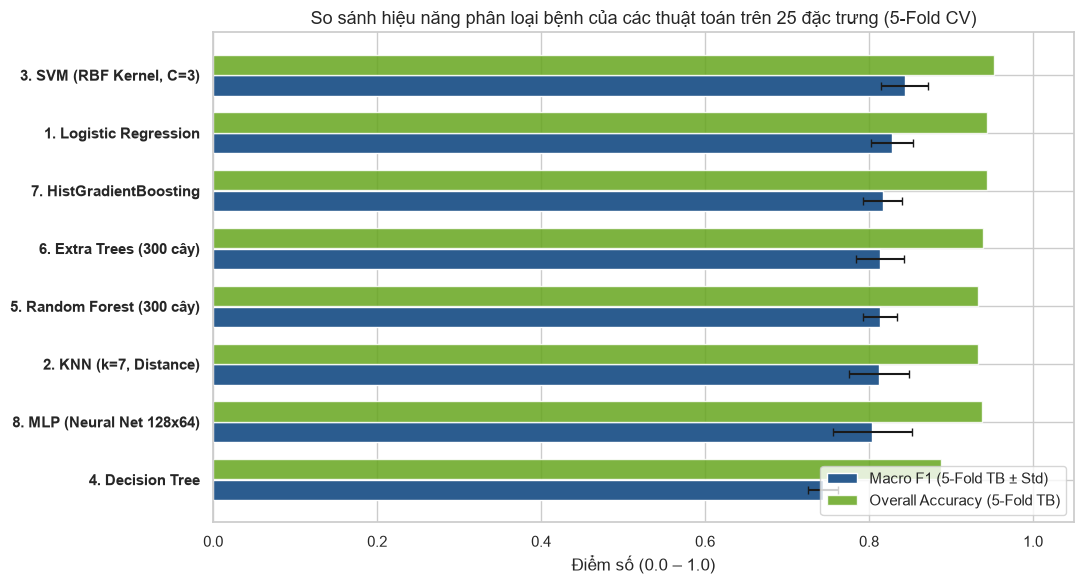

In [9]:
def get_models(class_weight_mode="sqrt"):
    if class_weight_mode == "none":
        cw = None
    elif class_weight_mode == "balanced":
        cw = "balanced"
    elif class_weight_mode == "sqrt":
        # Tính trọng số căn bậc hai toàn cục để truyền vào các bộ phân loại hỗ trợ dict class_weight
        all_y = df_feat["Disease_Type"].values
        w_raw = compute_class_weight("balanced", classes=np.array(CLASSES), y=all_y)
        cw = {c: float(np.sqrt(w)) for c, w in zip(CLASSES, w_raw)}
    else:
        cw = None

    # HistGradientBoosting mã hoá nhãn chuỗi thành 0..K-1 nên dict class_weight phải dùng khoá số nguyên
    cw_hgb = {i: cw[c] for i, c in enumerate(CLASSES)} if isinstance(cw, dict) else cw

    return {
        "0. Dummy (Đoán lớp đa số)": DummyClassifier(strategy="most_frequent"),
        "1. Logistic Regression": Pipeline([
            ("scaler", StandardScaler()),
            ("clf", LogisticRegression(max_iter=1000, class_weight=cw, random_state=SEED))
        ]),
        "2. KNN (k=7, Distance)": Pipeline([
            ("scaler", StandardScaler()),
            ("clf", KNeighborsClassifier(n_neighbors=7, weights="distance"))
        ]),
        "3. SVM (RBF Kernel, C=3)": Pipeline([
            ("scaler", StandardScaler()),
            ("clf", SVC(C=3.0, kernel="rbf", probability=True, class_weight=cw, random_state=SEED))
        ]),
        "4. Decision Tree": DecisionTreeClassifier(max_depth=12, min_samples_leaf=5, class_weight=cw, random_state=SEED),
        "5. Random Forest (300 cây)": RandomForestClassifier(
            n_estimators=300, max_depth=None, min_samples_leaf=2, class_weight=cw, n_jobs=-1, random_state=SEED
        ),
        "6. Extra Trees (300 cây)": ExtraTreesClassifier(
            n_estimators=300, max_depth=None, min_samples_leaf=2, class_weight=cw, n_jobs=-1, random_state=SEED
        ),
        "7. HistGradientBoosting": HistGradientBoostingClassifier(
            max_iter=200, learning_rate=0.08, max_leaf_nodes=31, class_weight=cw_hgb, random_state=SEED
        ),
        "8. MLP (Neural Net 128x64)": Pipeline([
            ("scaler", StandardScaler()),
            ("clf", MLPClassifier(hidden_layer_sizes=(128, 64), max_iter=500, early_stopping=True,
                                  alpha=1e-3, random_state=SEED))
        ]),
    }

def evaluate_cv_models(X_data, y_data, folds, models_dict):
    unique_folds = sorted(np.unique(folds))
    cv_splits = [(np.where(folds != f)[0], np.where(folds == f)[0]) for f in unique_folds]

    results = []
    oof_predictions = {}
    oof_probas = {}

    for name, model in models_dict.items():
        t0 = time.time()
        fold_acc, fold_bal_acc, fold_f1_macro, fold_f1_weighted = [], [], [], []
        y_oof_pred = np.empty_like(y_data, dtype=object)
        y_oof_prob = np.zeros((len(y_data), K), dtype=float)

        for train_idx, val_idx in cv_splits:
            X_tr, y_tr = X_data[train_idx], y_data[train_idx]
            X_va, y_va = X_data[val_idx], y_data[val_idx]

            model.fit(X_tr, y_tr)
            preds = model.predict(X_va)
            y_oof_pred[val_idx] = preds

            if hasattr(model, "predict_proba"):
                probs = model.predict_proba(X_va)
                # Đảm bảo thứ tự cột xác suất khớp với CLASSES
                model_classes = list(model.classes_)
                for c_idx, cls_name in enumerate(model_classes):
                    target_col = CLASSES.index(cls_name)
                    y_oof_prob[val_idx, target_col] = probs[:, c_idx]

            fold_acc.append(accuracy_score(y_va, preds))
            fold_bal_acc.append(balanced_accuracy_score(y_va, preds))
            fold_f1_macro.append(f1_score(y_va, preds, average="macro", zero_division=0))
            fold_f1_weighted.append(f1_score(y_va, preds, average="weighted", zero_division=0))

        # Tính F1 riêng cho từng lớp trên toàn bộ dự đoán Out-of-Fold (OOF)
        per_class_f1 = f1_score(y_data, y_oof_pred, labels=CLASSES, average=None, zero_division=0)
        per_class_rec = recall_score(y_data, y_oof_pred, labels=CLASSES, average=None, zero_division=0)

        results.append({
            "Mo_hinh": name,
            "Macro_F1_TB": round(np.mean(fold_f1_macro), 4),
            "Macro_F1_Std": round(np.std(fold_f1_macro), 4),
            "Balanced_Acc_TB": round(np.mean(fold_bal_acc), 4),
            "Accuracy_TB": round(np.mean(fold_acc), 4),
            "Weighted_F1_TB": round(np.mean(fold_f1_weighted), 4),
            "F1_BlackRot (Hiếm 4.7%)": round(per_class_f1[CLASSES.index("Black Rot")], 4),
            "F1_LeafBlight (Hiếm 7.4%)": round(per_class_f1[CLASSES.index("Leaf Blight")], 4),
            "F1_Esca": round(per_class_f1[CLASSES.index("Esca")], 4),
            "F1_Healthy": round(per_class_f1[CLASSES.index("Healthy")], 4),
            "Recall_BlackRot": round(per_class_rec[CLASSES.index("Black Rot")], 4),
            "Thoi_gian (s)": round(time.time() - t0, 2)
        })
        oof_predictions[name] = y_oof_pred
        oof_probas[name] = y_oof_prob

    df_res = pd.DataFrame(results).sort_values("Macro_F1_TB", ascending=False).reset_index(drop=True)
    return df_res, oof_predictions, oof_probas

X_full_mat = df_feat[FEATURE_COLS].values
y_full_vec = df_feat["Disease_Type"].values
folds_vec  = df_feat["Fold"].values

print("Đang huấn luyện và đánh giá 5-Fold Cross-Validation cho các mô hình (với trọng số Sqrt-Balanced)...")
models_sqrt = get_models(class_weight_mode="sqrt")
df_cv_results, oof_preds_dict, oof_probs_dict = evaluate_cv_models(X_full_mat, y_full_vec, folds_vec, models_sqrt)

display(df_cv_results)

# Trực quan hóa so sánh hiệu năng các mô hình
df_plot_cv = df_cv_results[df_cv_results["Mo_hinh"] != "0. Dummy (Đoán lớp đa số)"].iloc[::-1]
fig, ax = plt.subplots(figsize=(11, 6))
y_pos = np.arange(len(df_plot_cv))
bars1 = ax.barh(y_pos - 0.18, df_plot_cv["Macro_F1_TB"], height=0.35,
                xerr=df_plot_cv["Macro_F1_Std"], capsize=3, label="Macro F1 (5-Fold TB ± Std)", color="#2b5c8f")
bars2 = ax.barh(y_pos + 0.18, df_plot_cv["Accuracy_TB"], height=0.35,
                label="Overall Accuracy (5-Fold TB)", color="#66a61e", alpha=0.85)

ax.set_yticks(y_pos)
ax.set_yticklabels(df_plot_cv["Mo_hinh"], fontweight="bold")
ax.set_xlabel("Điểm số (0.0 – 1.0)")
ax.set_title("So sánh hiệu năng phân loại bệnh của các thuật toán trên 25 đặc trưng (5-Fold CV)", fontsize=13)
ax.set_xlim(0.0, 1.05)
ax.legend(loc="lower right")
plt.tight_layout()
savefig("bai1_so_sanh_mo_hinh_5fold_cv")
plt.show()

#### 📊 Giải thích kết quả: so sánh 9 mô hình bằng 5-fold CV (trọng số Sqrt)
- **Cell này làm gì:** huấn luyện và đánh giá 9 mô hình trên cùng 5 fold, trong đó `Dummy` (luôn đoán Healthy) là mốc tối thiểu.
- **Xếp hạng theo Macro-F1:** SVM RBF 0,8435 ± 0,029, Logistic Regression 0,8279, HistGradientBoosting 0,8167, Extra Trees 0,8136, Random Forest 0,8133, KNN 0,8118, MLP 0,8042 ± 0,049, Decision Tree 0,7435, Dummy 0,1739.
- **Accuracy gây hiểu nhầm:** các mô hình tốt đều đạt accuracy 93–95%, nhưng Macro-F1 chỉ 0,80–0,84. Khoảng cách này do hai lớp hiếm. Ngay cả `Dummy` cũng đạt accuracy 53,4% chỉ nhờ đoán Healthy, nên **chỉ số chính phải là Macro-F1 và Balanced Accuracy**.
- **F1 theo lớp của SVM:** Healthy 0,992, Esca 0,971 nhưng **Leaf Blight 0,760 và Black Rot 0,656** (recall Black Rot 0,656). Hai lớp hiếm là điểm nghẽn.
- **Chênh lệch giữa các mô hình top đầu không có ý nghĩa rõ ràng:** độ lệch chuẩn giữa các fold là 0,02–0,05, lớn hơn khoảng cách giữa SVM, Logistic Regression, HistGradientBoosting, Extra Trees, Random Forest và KNN (các thanh sai số trên biểu đồ chồng lên nhau). SVM đứng đầu về mặt số học, nhưng chưa thể kết luận nó tốt hơn hẳn các mô hình còn lại. MLP kém ổn định nhất (std 0,049).
- **Decision Tree đơn lẻ kém nhất trong nhóm mô hình thật** (0,7435), cho thấy mô hình tổ hợp, SVM hoặc mô hình tuyến tính có điều chuẩn phù hợp hơn với bộ đặc trưng này.
- **Thời gian:** SVM 0,71 giây, HistGradientBoosting 24,8 giây, nên SVM vừa nhanh vừa đứng đầu.

### 5.1. Đối chiếu thực nghiệm 3 chiến lược xử lý mất cân bằng lớp (`None` vs `Sqrt-Balanced` vs `Balanced`)

#### 📝 Giải thích cell: Thực nghiệm chọn chiến lược Trọng số lớp tối ưu
**Mục đích:** Chứng minh bằng số liệu thực tế lý do chọn trọng số lớp khi dữ liệu bị lệch nặng (Black Rot chỉ có 4,7%). Ta chạy 3 mô hình mạnh nhất (**SVM RBF**, **Random Forest**, **HistGradientBoosting**) qua cả 3 chế độ:
- `none`: Không dùng trọng số.
- `sqrt`: Trọng số căn bậc hai tỷ lệ nghịch tần suất lớp.
- `balanced`: Trọng số cân bằng tuyệt đối tỷ lệ nghịch tần suất lớp.

Bảng kết quả dưới đây sẽ cho thấy rõ sự đánh đổi giữa **Recall của lớp hiếm (`Black Rot`)** và **Macro F1 tổng thể**.

In [10]:
weight_modes = ["none", "sqrt", "balanced"]
weight_comp_rows = []

for mode in weight_modes:
    m_dict = get_models(class_weight_mode=mode)
    # Chọn 3 mô hình tiêu biểu nhất để đối chiếu
    selected_keys = ["3. SVM (RBF Kernel, C=3)", "5. Random Forest (300 cây)", "7. HistGradientBoosting"]
    sub_models = {k: m_dict[k] for k in selected_keys}
    df_sub, _, _ = evaluate_cv_models(X_full_mat, y_full_vec, folds_vec, sub_models)
    for _, r in df_sub.iterrows():
        weight_comp_rows.append({
            "Mo_hinh": r["Mo_hinh"],
            "Che_do_Weight": mode,
            "Macro_F1": r["Macro_F1_TB"],
            "Balanced_Acc": r["Balanced_Acc_TB"],
            "Accuracy": r["Accuracy_TB"],
            "F1_BlackRot": r["F1_BlackRot (Hiếm 4.7%)"],
            "Recall_BlackRot": r["Recall_BlackRot"],
            "F1_LeafBlight": r["F1_LeafBlight (Hiếm 7.4%)"],
        })

df_weight_comp = pd.DataFrame(weight_comp_rows)
print("Bảng đối chiếu ảnh hưởng của Chiến lược Trọng số lớp (Class Weight) trên 5-Fold CV:")
display(df_weight_comp.pivot(index="Mo_hinh", columns="Che_do_Weight",
                             values=["Macro_F1", "Balanced_Acc", "Recall_BlackRot", "F1_BlackRot"]))

Bảng đối chiếu ảnh hưởng của Chiến lược Trọng số lớp (Class Weight) trên 5-Fold CV:


Macro_F1                 Balanced_Acc          \
Che_do_Weight              balanced    none    sqrt     balanced    none   
Mo_hinh                                                                    
3. SVM (RBF Kernel, C=3)     0.8397  0.8409  0.8435       0.8428  0.8334   
5. Random Forest (300 cây)   0.8217  0.8015  0.8133       0.8205  0.7834   
7. HistGradientBoosting      0.8144  0.8199  0.8167       0.8099  0.8105   

                                   Recall_BlackRot                  \
Che_do_Weight                 sqrt        balanced    none    sqrt   
Mo_hinh                                                              
3. SVM (RBF Kernel, C=3)    0.8427          0.6771  0.6146  0.6562   
5. Random Forest (300 cây)  0.8036          0.6042  0.5000  0.5729   
7. HistGradientBoosting     0.8124          0.5312  0.5521  0.5521   

                           F1_BlackRot                  
Che_do_Weight                 balanced    none    sqrt  
Mo_hinh                                                 
3. SVM (RBF Kernel, C=3)        0.6599  0.6484  0.6562  
5. Random Forest (300 cây)      0.6339  0.5680  0.6111  
7. HistGradientBoosting         0.5763  0.5922  0.5856

#### 📊 Giải thích kết quả: ảnh hưởng của trọng số lớp
- **Cell này làm gì:** chạy 3 mô hình mạnh với 3 chế độ trọng số (`none`, `sqrt`, `balanced`) để xem chế độ nào tốt hơn.
- **Macro-F1 gần như không đổi theo trọng số:** SVM 0,8397 (balanced), 0,8409 (none), 0,8435 (sqrt); HistGradientBoosting 0,8144 / 0,8199 / 0,8167; Random Forest 0,8217 / 0,8015 / 0,8133. Chênh lệch tối đa khoảng 0,02, nhỏ hơn độ lệch chuẩn giữa các fold (khoảng 0,02–0,03).
- **Tác động chỉ rõ ở recall của Black Rot với SVM và Random Forest:** SVM tăng từ 0,615 (none) lên 0,656 (sqrt) và 0,677 (balanced); Random Forest từ 0,500 lên 0,573 và 0,604. Với HistGradientBoosting trọng số không giúp (0,552 / 0,552 / 0,531).
- **Kết luận thận trọng:** trọng số lớp giúp **tăng nhẹ độ nhạy của Black Rot** ở SVM và Random Forest nhưng **không cải thiện Macro-F1 một cách chắc chắn**, và `sqrt` không vượt trội so với `balanced`. Việc chọn `sqrt` là một lựa chọn hợp lý nhưng không phải kết quả được "chứng minh" bởi bảng này.

### 6. Nghiên cứu loại bỏ (Ablation Study) & Độ quan trọng đặc trưng (Feature Importance)

#### 📝 Giải thích cell: Chứng minh vai trò của 3 nhóm đặc trưng (Màu sắc + Kết cấu + Hình dạng)
**Câu hỏi đặt ra từ đề bài:** *"Bệnh lá nho biểu hiện qua sự thay đổi màu sắc, kết cấu và hình dạng trên lá. Liệu chỉ dùng Màu sắc có đủ không, hay bắt buộc phải kết hợp cả Kết cấu (GLCM) và Hình dạng (Hu Moments)?"*

**Phương pháp kiểm chứng (Ablation Study):**
Ta huấn luyện cùng một mô hình chuẩn trên từng nhóm đặc trưng riêng lẻ và các tổ hợp:
1. Chỉ **Hình dạng** (`Hu Moments` - 4 đặc trưng)
2. Chỉ **Kết cấu** (`GLCM` - 12 đặc trưng)
3. Chỉ **Màu sắc** (`HSV` - 9 đặc trưng)
4. Kết hợp **Màu sắc + Kết cấu** (`HSV + GLCM` - 21 đặc trưng)
5. Kết hợp **Đầy đủ cả 3 nhóm** (`HSV + GLCM + Hu Moments` - 25 đặc trưng)

Đồng thời, sử dụng **Permutation Importance (Độ quan trọng hoán vị)** để đo xem khi làm xáo trộn ngẫu nhiên từng đặc trưng thì điểm `Macro F1` bị sụt giảm bao nhiêu.

Mô hình tốt nhất được chọn để phân tích chuyên sâu: 3. SVM (RBF Kernel, C=3)

Kết quả Ablation Study (Đóng góp của từng nhóm đặc trưng thị giác):


,To_hop_dac_trung,So_chieu,Macro_F1_TB,Balanced_Acc_TB,Accuracy_TB,F1_BlackRot,F1_LeafBlight,F1_Esca,F1_Healthy
0,1. Chỉ Hình dạng (Hu Moments - 4 cột),4,0.3771,0.3814,0.6214,0.2275,0.0244,0.5315,0.7327
1,2. Chỉ Kết cấu (GLCM - 12 cột),12,0.7292,0.7439,0.8544,0.5540,0.5935,0.8459,0.9257
2,3. Chỉ Màu sắc (HSV - 9 cột),9,0.8115,0.8124,0.9419,0.5306,0.7733,0.9565,0.9923
3,4. Màu sắc + Hình dạng (HSV + Hu - 13 cột),13,0.8079,0.8094,0.9389,0.5641,0.7285,0.9550,0.9909
4,5. Màu sắc + Kết cấu (HSV + GLCM - 21 cột),21,0.8558,0.8595,0.9565,0.6832,0.7755,0.9752,0.9941
5,6. Kết hợp cả 3 nhóm (Đầy đủ 25 cột),25,0.8435,0.8427,0.9521,0.6562,0.7600,0.9710,0.9922


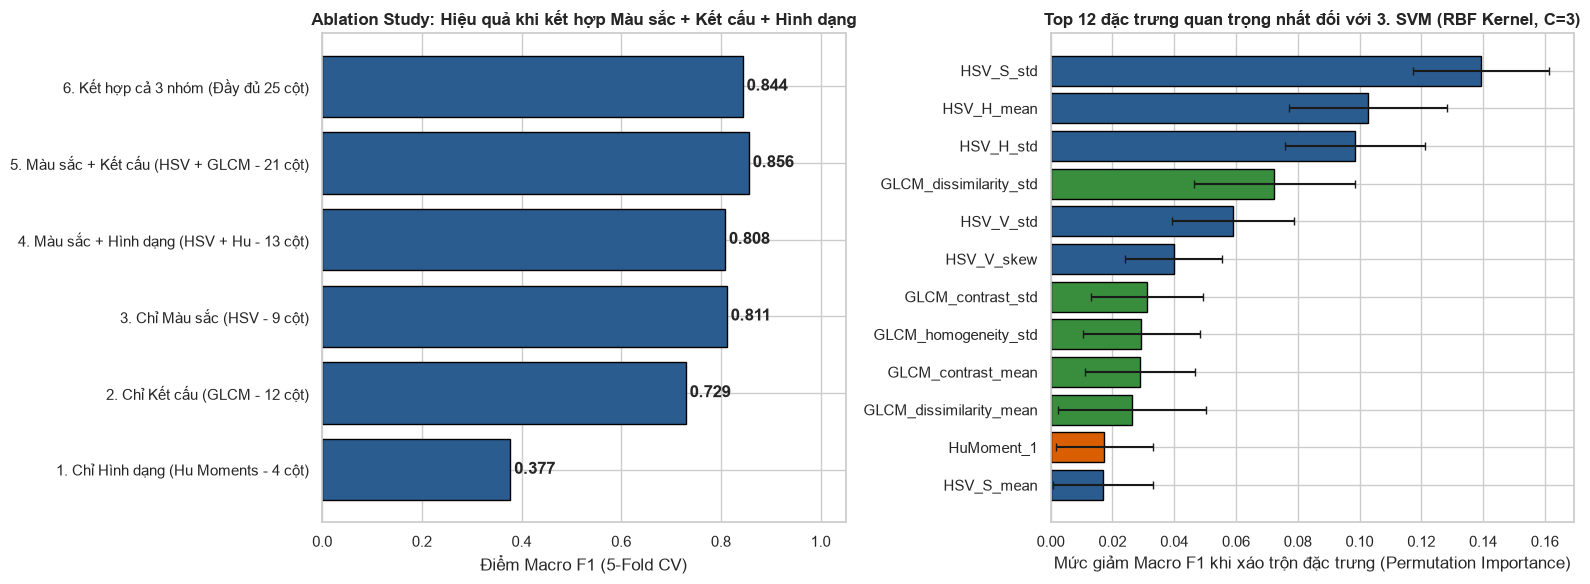

In [11]:
feature_subsets = {
    "1. Chỉ Hình dạng (Hu Moments - 4 cột)": HU_COLS,
    "2. Chỉ Kết cấu (GLCM - 12 cột)": GLCM_COLS,
    "3. Chỉ Màu sắc (HSV - 9 cột)": HSV_COLS,
    "4. Màu sắc + Hình dạng (HSV + Hu - 13 cột)": HSV_COLS + HU_COLS,
    "5. Màu sắc + Kết cấu (HSV + GLCM - 21 cột)": HSV_COLS + GLCM_COLS,
    "6. Kết hợp cả 3 nhóm (Đầy đủ 25 cột)": FEATURE_COLS,
}

# Chọn mô hình đạt Macro F1 cao nhất ở mục 5 để chạy Ablation Study
best_model_name = df_cv_results.iloc[0]["Mo_hinh"]
print(f"Mô hình tốt nhất được chọn để phân tích chuyên sâu: {best_model_name}\n")

ablation_rows = []
for subset_name, cols in feature_subsets.items():
    X_sub = df_feat[cols].values
    model_instance = get_models(class_weight_mode="sqrt")[best_model_name]
    df_ab, _, _ = evaluate_cv_models(X_sub, y_full_vec, folds_vec, {best_model_name: model_instance})
    r = df_ab.iloc[0]
    ablation_rows.append({
        "To_hop_dac_trung": subset_name,
        "So_chieu": len(cols),
        "Macro_F1_TB": r["Macro_F1_TB"],
        "Balanced_Acc_TB": r["Balanced_Acc_TB"],
        "Accuracy_TB": r["Accuracy_TB"],
        "F1_BlackRot": r["F1_BlackRot (Hiếm 4.7%)"],
        "F1_LeafBlight": r["F1_LeafBlight (Hiếm 7.4%)"],
        "F1_Esca": r["F1_Esca"],
        "F1_Healthy": r["F1_Healthy"],
    })

df_ablation = pd.DataFrame(ablation_rows)
print("Kết quả Ablation Study (Đóng góp của từng nhóm đặc trưng thị giác):")
display(df_ablation)

# Vẽ biểu đồ Ablation Study + Permutation Importance cạnh nhau
X_tr_split = df_feat.loc[df_feat["Split"] == "train", FEATURE_COLS].values
y_tr_split = df_feat.loc[df_feat["Split"] == "train", "Disease_Type"].values
X_va_split = df_feat.loc[df_feat["Split"] == "val", FEATURE_COLS].values
y_va_split = df_feat.loc[df_feat["Split"] == "val", "Disease_Type"].values

best_clf_perm = get_models(class_weight_mode="sqrt")[best_model_name]
best_clf_perm.fit(X_tr_split, y_tr_split)
perm_imp = permutation_importance(best_clf_perm, X_va_split, y_va_split,
                                  scoring="f1_macro", n_repeats=15, random_state=SEED, n_jobs=-1)

df_perm = pd.DataFrame({
    "Dac_trung": FEATURE_COLS,
    "Nhom": [feature_family(c) for c in FEATURE_COLS],
    "Muc_giam_Macro_F1": perm_imp.importances_mean,
    "Std": perm_imp.importances_std
}).sort_values("Muc_giam_Macro_F1", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Biểu đồ 1: Ablation Study
axes[0].barh(df_ablation["To_hop_dac_trung"], df_ablation["Macro_F1_TB"], color="#2b5c8f", edgecolor="black", label="Macro F1")
for i, v in enumerate(df_ablation["Macro_F1_TB"]):
    axes[0].text(v + 0.008, i, f"{v:.3f}", va="center", fontweight="bold")
axes[0].set_xlim(0.0, 1.05)
axes[0].set_xlabel("Điểm Macro F1 (5-Fold CV)")
axes[0].set_title("Ablation Study: Hiệu quả khi kết hợp Màu sắc + Kết cấu + Hình dạng", fontsize=12, fontweight="bold")

# Biểu đồ 2: Top 12 Permutation Importance
top12_perm = df_perm.head(12).iloc[::-1]
p_colors = [palette_map[g] for g in top12_perm["Nhom"]]
axes[1].barh(top12_perm["Dac_trung"], top12_perm["Muc_giam_Macro_F1"], xerr=top12_perm["Std"],
             color=p_colors, edgecolor="black", capsize=3)
axes[1].set_xlabel("Mức giảm Macro F1 khi xáo trộn đặc trưng (Permutation Importance)")
axes[1].set_title(f"Top 12 đặc trưng quan trọng nhất đối với {best_model_name}", fontsize=12, fontweight="bold")

plt.tight_layout()
savefig("bai1_ablation_study_va_feature_importance")
plt.show()

#### 📊 Giải thích kết quả: ablation và độ quan trọng đặc trưng (mô hình SVM, 5-fold)
- **Cell này làm gì:** huấn luyện SVM trên từng nhóm đặc trưng và các tổ hợp để đo đóng góp của màu, kết cấu và hình dạng. Biểu đồ bên phải dùng Permutation Importance: xáo trộn từng đặc trưng và đo Macro-F1 giảm bao nhiêu.
- **Kết quả ablation (Macro-F1):**

| Tổ hợp đặc trưng | Số cột | Macro-F1 |
|---|---|---|
| Chỉ hình dạng (Hu) | 4 | 0,377 |
| Chỉ kết cấu (GLCM) | 12 | 0,729 |
| Chỉ màu sắc (HSV) | 9 | 0,812 |
| Màu + hình dạng | 13 | 0,808 |
| **Màu + kết cấu** | 21 | **0,856** |
| Cả 3 nhóm | 25 | 0,844 |

- **Màu sắc là nhóm mạnh nhất** (0,812 một mình). Thêm kết cấu tăng lên 0,856, đặc biệt cải thiện Black Rot (F1 từ 0,531 lên 0,683).
- **Hình dạng (Hu) không đóng góp:** một mình chỉ đạt 0,377, và thêm vào bộ màu hoặc bộ màu + kết cấu **không tăng mà giảm nhẹ** (0,812 → 0,808; 0,856 → 0,844). Mức giảm nằm trong dao động giữa các fold nên không cần diễn giải là có hại, nhưng **không có bằng chứng Hu có ích**. Điều này khớp với việc `HuMoment_1` tương quan mạnh với độ sáng (mục 4).
- **Permutation Importance:** quan trọng nhất là `HSV_S_std` (giảm khoảng 0,14), `HSV_H_mean` và `HSV_H_std` (khoảng 0,10), rồi `GLCM_dissimilarity_std` (khoảng 0,07), `HSV_V_std` (khoảng 0,06). `HuMoment_1` chỉ khoảng 0,02 và thanh sai số chạm gần 0. Các thanh sai số khá dài nên thứ hạng giữa các đặc trưng ở nửa dưới không chắc chắn.
- **Kết luận cho báo cáo:** bộ **Màu sắc + Kết cấu (21 cột)** là tổ hợp tốt nhất; có thể bỏ nhóm Hu Moments mà không mất hiệu năng.

### 7. Kiểm toán hiện tượng "Học đường tắt" theo điều kiện sáng (Shortcut Learning Audit)

#### 📝 Giải thích cell: Mô hình học triệu chứng bệnh thật hay chỉ học độ sáng của ảnh?
**Vấn đề phát hiện từ Bước 03:**
- Ở mục `5.1` của notebook `03_Image_Preprocessing`, ta phát hiện độ sáng (`Brightness`) và độ tương phản (`Contrast`) khác biệt có ý nghĩa thống kê giữa các lớp bệnh ($p = 1,38 \times 10^{-29}$): ảnh `Black Rot` sáng hơn hẳn (median 135,3) và ít tương phản hơn `Healthy`.
- Điều này đặt ra câu hỏi phản biện rất quan trọng: *"Liệu mô hình đạt điểm cao là do nhận diện đúng vết bệnh, hay do học vẹt đường tắt (Shortcut Learning) cứ thấy ảnh sáng/mờ là đoán Black Rot?"*

**Thiết kế thí nghiệm kiểm chứng (3 bài test):**
1. **Test 1 – Chỉ dùng Độ sáng & Độ tương phản (`Brightness`, `Contrast`, `HSV_V_*`)**: Xem nếu không có thông tin màu sắc (Hue/Saturation), kết cấu (GLCM) và hình dạng (Hu Moments), chỉ riêng độ sáng giải thích được bao nhiêu % kết quả.
2. **Test 2 – Loại bỏ hoàn toàn kênh cường độ sáng (`Bỏ HSV_V_mean, HSV_V_std, HSV_V_skew`)**: Chỉ cho mô hình học trên tông màu (`Hue`), độ đậm màu (`Saturation`), kết cấu (`GLCM`) và hình dạng (`Hu Moments`). Nếu sau khi bỏ kênh sáng `V`, mô hình vẫn giữ được Macro F1 và Accuracy cao tương đương bản đầy đủ, ta có bằng chứng cho thấy mô hình **không phụ thuộc riêng vào kênh độ sáng `V`** (lưu ý: một số đặc trưng còn lại như `GLCM_contrast` hay `HuMoment_1` vẫn tương quan với độ sáng, nên chưa loại trừ hoàn toàn ảnh hưởng gián tiếp)
3. **Test 3 – Đánh giá độ ổn định theo 3 phân vị Độ sáng (Ảnh Tối / Trung bình / Sáng)**: Chia tập dữ liệu thành 3 nhóm theo độ sáng thực tế và kiểm tra độ chính xác trên từng nhóm.

In [12]:
# Danh sách đặc trưng KHÔNG chứa kênh cường độ sáng V (chỉ giữ Hue, Saturation, GLCM, HuMoments)
NO_BRIGHTNESS_COLS = [c for c in FEATURE_COLS if not c.startswith("HSV_V_")]
ONLY_BRIGHTNESS_COLS = [c for c in FEATURE_COLS if c.startswith("HSV_V_")]

shortcut_experiments = {
    "1. Chỉ dùng kênh Độ sáng (HSV_V - 3 cột)": df_feat[ONLY_BRIGHTNESS_COLS].values,
    "2. Loại bỏ hoàn toàn Độ sáng (Chỉ H, S, GLCM, Hu - 22 cột)": df_feat[NO_BRIGHTNESS_COLS].values,
    "3. Bộ đặc trưng đầy đủ (25 cột)": df_feat[FEATURE_COLS].values,
}

shortcut_rows = []
for exp_name, X_exp in shortcut_experiments.items():
    clf_exp = get_models(class_weight_mode="sqrt")[best_model_name]
    df_sc, _, _ = evaluate_cv_models(X_exp, y_full_vec, folds_vec, {best_model_name: clf_exp})
    r = df_sc.iloc[0]
    shortcut_rows.append({
        "Thi_nghiem_Kiem_toan": exp_name,
        "Macro_F1_TB": r["Macro_F1_TB"],
        "Balanced_Acc_TB": r["Balanced_Acc_TB"],
        "Accuracy_TB": r["Accuracy_TB"],
        "F1_BlackRot": r["F1_BlackRot (Hiếm 4.7%)"],
        "F1_LeafBlight": r["F1_LeafBlight (Hiếm 7.4%)"],
        "F1_Esca": r["F1_Esca"],
        "F1_Healthy": r["F1_Healthy"],
    })

df_shortcut = pd.DataFrame(shortcut_rows)
print("Kết quả Kiểm toán Học đường tắt (Shortcut Learning Audit):")
display(df_shortcut)

# Kiểm tra độ chính xác của mô hình (OOF predictions) trên 3 mức độ sáng của ảnh: Thấp / Trung bình / Cao
if "Brightness" in df_feat.columns:
    df_feat["Nhom_Do_Sang"] = pd.qcut(df_feat["Brightness"], q=3, labels=["1. Ảnh Tối (Q1)", "2. Trung bình (Q2)", "3. Ảnh Sáng (Q3)"])
    best_oof_preds = oof_preds_dict[best_model_name]
    bright_eval_rows = []
    for b_grp, sub in df_feat.groupby("Nhom_Do_Sang", observed=False):
        idx = sub.index.values
        y_true_sub = y_full_vec[idx]
        y_pred_sub = best_oof_preds[idx]
        bright_eval_rows.append({
            "Phan_vi_Do_sang": b_grp,
            "So_anh": len(idx),
            "Khoang_Brightness": f"{sub['Brightness'].min():.1f} – {sub['Brightness'].max():.1f}",
            "Accuracy": round(accuracy_score(y_true_sub, y_pred_sub), 4),
            "Macro_F1": round(f1_score(y_true_sub, y_pred_sub, average="macro", zero_division=0), 4),
            "Balanced_Acc": round(balanced_accuracy_score(y_true_sub, y_pred_sub), 4),
        })
    print("\nĐộ ổn định của mô hình qua 3 vùng điều kiện ánh sáng khác nhau:")
    display(pd.DataFrame(bright_eval_rows))

Kết quả Kiểm toán Học đường tắt (Shortcut Learning Audit):


,Thi_nghiem_Kiem_toan,Macro_F1_TB,Balanced_Acc_TB,Accuracy_TB,F1_BlackRot,F1_LeafBlight,F1_Esca,F1_Healthy
0,1. Chỉ dùng kênh Độ sáng (HSV_V - 3 cột),0.6108,0.6024,0.8188,0.3699,0.3562,0.7906,0.9324
1,"2. Loại bỏ hoàn toàn Độ sáng (Chỉ H, S, GLCM, ...",0.8498,0.8519,0.9507,0.6804,0.7682,0.9674,0.9890
2,3. Bộ đặc trưng đầy đủ (25 cột),0.8435,0.8427,0.9521,0.6562,0.7600,0.9710,0.9922



Độ ổn định của mô hình qua 3 vùng điều kiện ánh sáng khác nhau:


,Phan_vi_Do_sang,So_anh,Khoang_Brightness,Accuracy,Macro_F1,Balanced_Acc
0,1. Ảnh Tối (Q1),683,52.0 – 109.7,0.9722,0.7541,0.7477
1,2. Trung bình (Q2),682,109.7 – 124.5,0.9619,0.8149,0.8180
2,3. Ảnh Sáng (Q3),682,124.5 – 180.6,0.9223,0.8612,0.8599


#### 📊 Giải thích kết quả: kiểm toán "học đường tắt" theo độ sáng
- **Cell này làm gì:** kiểm tra mô hình có dựa vào độ sáng thay vì triệu chứng bệnh hay không, qua 3 phép thử.
- **Phép thử 1 (chỉ dùng kênh sáng `HSV_V`, 3 cột):** Macro-F1 **0,611**, accuracy 0,819 (mốc đoán bừa là 0,174). Như vậy chỉ riêng độ sáng đã giải thích được khá nhiều, nên **nguy cơ đường tắt là có thật**, đúng như phát hiện ở bước 03.
- **Phép thử 2 (bỏ hoàn toàn `HSV_V_*`):** Macro-F1 **0,850**, tương đương và thậm chí nhỉnh hơn bộ đầy đủ (0,844), F1 Black Rot 0,680 so với 0,656. Mô hình **không phụ thuộc riêng vào kênh sáng `V`**.
- **Giới hạn của phép thử 2:** kênh `V` bị bỏ nhưng một số đặc trưng còn lại vẫn liên quan đến độ sáng và độ tương phản (`HuMoment_1` tương quan khoảng −0,9 với `HSV_V_skew`; `GLCM_contrast` phản ánh độ tương phản). Vì vậy kết quả này **chưa loại trừ hoàn toàn** ảnh hưởng gián tiếp của điều kiện sáng.
- **Phép thử 3 (3 vùng sáng):** accuracy giảm dần khi ảnh sáng hơn (tối 0,972, trung bình 0,962, sáng 0,922) trong khi Macro-F1 lại tăng (0,754, 0,815, 0,861). Sự đảo chiều này chủ yếu do **thành phần lớp khác nhau giữa các nhóm**: ảnh Black Rot sáng hơn nên nhóm sáng có nhiều ảnh lớp hiếm hơn (khó hơn nên accuracy thấp hơn, nhưng macro-F1 tính trên nhiều mẫu lớp hiếm hơn nên ổn định hơn). Vì vậy mô hình **không đều giữa các vùng sáng**, nhưng cell này chưa tách được ảnh hưởng của độ sáng khỏi ảnh hưởng của thành phần lớp. Nên bổ sung bảng số ảnh từng lớp trong mỗi vùng sáng trước khi kết luận.

### 8. Đánh giá trên tập Hold-out Test, Ma trận nhầm lẫn, Đường cong ROC / PR & Phân tích lỗi

#### 📝 Giải thích cell: Đánh giá độc lập trên tập Test và Phân tích chẩn đoán lỗi
**Mục đích:**
1. Huấn luyện mô hình tốt nhất trên tập `train + val` (85% dữ liệu) và đánh giá độc lập trên tập **`test` (15% dữ liệu giữ kín)**, đồng thời hiển thị **Ma trận nhầm lẫn (Confusion Matrix)** của cả tập Test lẫn toàn bộ dự đoán Out-of-Fold (2.047 ảnh).
2. Vẽ đường cong **ROC (One-vs-Rest)** và **Precision-Recall (PR Curve)**: Với các lớp thiểu số như `Black Rot` (4,7%) và `Leaf Blight` (7,4%), đường cong **Precision-Recall (Average Precision - AP)** phản ánh chất lượng phát hiện bệnh chính xác hơn nhiều so với ROC-AUC (vốn dễ cao ảo do số lượng mẫu âm tính thật `True Negative` quá lớn).
3. **Hiển thị trực quan các bức ảnh bị phân loại nhầm (Error Analysis Gallery)**: Mở trực tiếp file ảnh lá nho mà mô hình đoán sai để hiểu nguyên nhân thực tế (ví dụ: vết cháy lá `Leaf Blight` giai đoạn đầu hay vết sởi `Esca` có màu nâu vàng tương đồng nhau).

=== KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH [3. SVM (RBF Kernel, C=3)] TRÊN TẬP HOLD-OUT TEST (N = 308) ===
Accuracy          : 0.9545
Balanced Accuracy : 0.8546
Macro F1-Score    : 0.8591
Weighted F1-Score : 0.9541

Báo cáo chi tiết từng lớp bệnh trên tập Hold-out Test:
              precision    recall  f1-score   support

   Black Rot     0.7143    0.6667    0.6897        15
        Esca     0.9720    0.9811    0.9765       106
     Healthy     0.9878    0.9878    0.9878       164
 Leaf Blight     0.7826    0.7826    0.7826        23

    accuracy                         0.9545       308
   macro avg     0.8642    0.8546    0.8591       308
weighted avg     0.9537    0.9545    0.9541       308



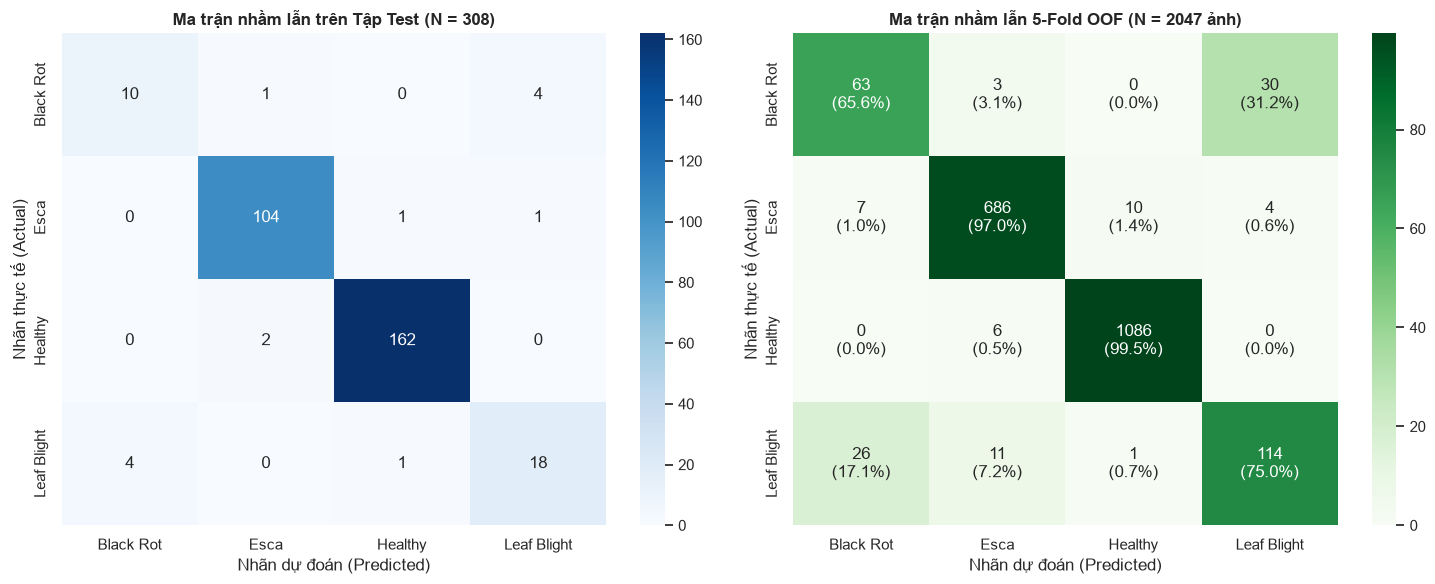

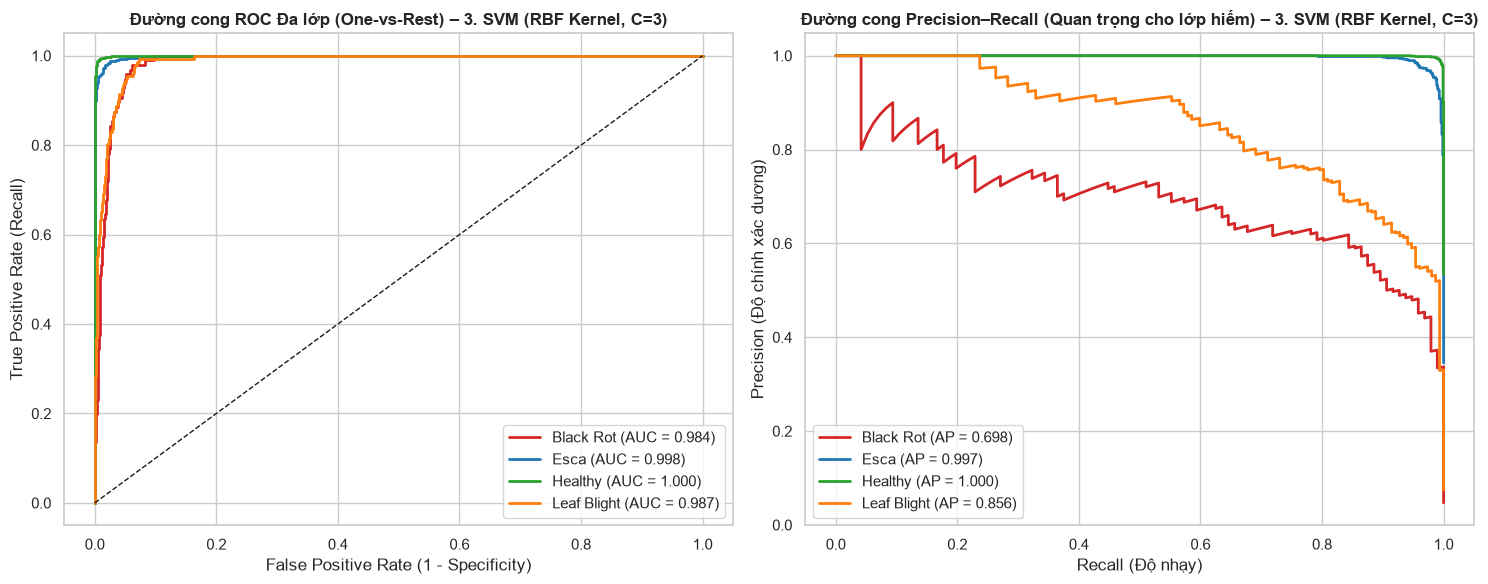

In [13]:
# Chia tập Train+Val (85%) để huấn luyện cuối và Test (15%) để kiểm thử độc lập
trainval_mask = df_feat["Split"].isin(["train", "val"]).values
test_mask     = (df_feat["Split"] == "test").values

X_trainval, y_trainval = X_full_mat[trainval_mask], y_full_vec[trainval_mask]
X_test, y_test         = X_full_mat[test_mask], y_full_vec[test_mask]

final_ml_model = get_models(class_weight_mode="sqrt")[best_model_name]
final_ml_model.fit(X_trainval, y_trainval)

y_test_pred = final_ml_model.predict(X_test)
y_test_prob = final_ml_model.predict_proba(X_test)

print(f"=== KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH [{best_model_name}] TRÊN TẬP HOLD-OUT TEST (N = {len(y_test)}) ===")
print(f"Accuracy          : {accuracy_score(y_test, y_test_pred):.4f}")
print(f"Balanced Accuracy : {balanced_accuracy_score(y_test, y_test_pred):.4f}")
print(f"Macro F1-Score    : {f1_score(y_test, y_test_pred, average='macro'):.4f}")
print(f"Weighted F1-Score : {f1_score(y_test, y_test_pred, average='weighted'):.4f}\n")
print("Báo cáo chi tiết từng lớp bệnh trên tập Hold-out Test:")
print(classification_report(y_test, y_test_pred, target_names=CLASSES, digits=4))

# Vẽ Ma trận nhầm lẫn: (1) Trên tập Hold-out Test và (2) Trên toàn bộ 5-Fold Out-of-Fold (2.047 ảnh)
y_oof_best = oof_preds_dict[best_model_name]
y_oof_prob_best = oof_probs_dict[best_model_name]

cm_test = confusion_matrix(y_test, y_test_pred, labels=CLASSES)
cm_oof  = confusion_matrix(y_full_vec, y_oof_best, labels=CLASSES)
cm_oof_pct = cm_oof.astype(float) / cm_oof.sum(axis=1, keepdims=True) * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.heatmap(cm_test, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[0])
axes[0].set_title(f"Ma trận nhầm lẫn trên Tập Test (N = {len(y_test)})", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Nhãn dự đoán (Predicted)")
axes[0].set_ylabel("Nhãn thực tế (Actual)")

# Hiển thị cả số lượng và tỷ lệ % trên ma trận 5-Fold OOF
annot_oof = np.empty_like(cm_oof, dtype=object)
for i in range(K):
    for j in range(K):
        annot_oof[i, j] = f"{cm_oof[i, j]}\n({cm_oof_pct[i, j]:.1f}%)"

sns.heatmap(cm_oof_pct, annot=annot_oof, fmt="", cmap="Greens", xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[1])
axes[1].set_title(f"Ma trận nhầm lẫn 5-Fold OOF (N = {len(y_full_vec)} ảnh)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Nhãn dự đoán (Predicted)")
axes[1].set_ylabel("Nhãn thực tế (Actual)")

plt.tight_layout()
savefig("bai1_confusion_matrix_test_va_oof")
plt.show()

# Vẽ đường cong ROC (One-vs-Rest) và Precision-Recall (PR Curve) trên dự đoán 5-Fold OOF
y_full_bin = label_binarize(y_full_vec, classes=CLASSES)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for i, cls_name in enumerate(CLASSES):
    fpr, tpr, _ = roc_curve(y_full_bin[:, i], y_oof_prob_best[:, i])
    auc_val = roc_auc_score(y_full_bin[:, i], y_oof_prob_best[:, i])
    axes[0].plot(fpr, tpr, lw=2, color=class_palette[cls_name], label=f"{cls_name} (AUC = {auc_val:.3f})")

    prec, rec, _ = precision_recall_curve(y_full_bin[:, i], y_oof_prob_best[:, i])
    ap_val = average_precision_score(y_full_bin[:, i], y_oof_prob_best[:, i])
    axes[1].plot(rec, prec, lw=2, color=class_palette[cls_name], label=f"{cls_name} (AP = {ap_val:.3f})")

axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set_xlabel("False Positive Rate (1 - Specificity)")
axes[0].set_ylabel("True Positive Rate (Recall)")
axes[0].set_title(f"Đường cong ROC Đa lớp (One-vs-Rest) – {best_model_name}", fontsize=12, fontweight="bold")
axes[0].legend(loc="lower right")

axes[1].set_xlabel("Recall (Độ nhạy)")
axes[1].set_ylabel("Precision (Độ chính xác dương)")
axes[1].set_title(f"Đường cong Precision–Recall (Quan trọng cho lớp hiếm) – {best_model_name}", fontsize=12, fontweight="bold")
axes[1].legend(loc="lower left")

plt.tight_layout()
savefig("bai1_roc_va_pr_curves")
plt.show()

#### 📊 Giải thích kết quả: đánh giá trên test, ma trận nhầm lẫn, ROC và PR (mô hình SVM)
- **Cell này làm gì:** huấn luyện SVM trên train + val (1.739 ảnh), đánh giá một lần trên test (308 ảnh) và vẽ ma trận nhầm lẫn, đường cong ROC và Precision–Recall (ROC và PR vẽ từ dự đoán 5-fold OOF).
- **Số liệu test:** accuracy 0,9545 (294/308), balanced accuracy 0,8546, **Macro-F1 0,8591**. Gần với kết quả 5-fold (0,8435 ± 0,029), nên không có dấu hiệu test "may mắn" bất thường.

| Lớp | Precision | Recall | F1 | Số ảnh | Recall (khoảng tin cậy 95%) |
|---|---|---|---|---|---|
| Black Rot | 0,714 | 0,667 | 0,690 | 15 | 10/15, khoảng 0,42–0,85 |
| Esca | 0,972 | 0,981 | 0,977 | 106 | 104/106 |
| Healthy | 0,988 | 0,988 | 0,988 | 164 | 162/164 |
| Leaf Blight | 0,783 | 0,783 | 0,783 | 23 | 18/23, khoảng 0,58–0,90 |

- **Ma trận nhầm lẫn (test):** 14 lỗi, trong đó **8 lỗi là nhầm giữa Black Rot và Leaf Blight** (4 chiều mỗi hướng). Ma trận 5-fold OOF (2.047 ảnh) cùng xu hướng: Healthy đúng 99,5%, Esca 97,0%, **Leaf Blight 75,0% và Black Rot 65,6%**; 31,2% Black Rot bị đoán thành Leaf Blight và 17,1% Leaf Blight bị đoán thành Black Rot.
- **ROC-AUC (OOF)** rất cao cho cả hai lớp hiếm (Black Rot 0,984, Leaf Blight 0,987, Esca 0,998, Healthy 1,000), nghĩa là mô hình **xếp hạng** các ảnh khá tốt. Nhưng **Average Precision** thấp hơn đáng kể ở lớp hiếm (Black Rot **0,698**, Leaf Blight 0,856): khi muốn bắt thêm Black Rot, độ chính xác tụt nhanh (còn khoảng 0,6 ở recall 0,7). ROC làm lớp hiếm trông tốt hơn thực tế vì số mẫu âm rất lớn, nên **đường PR phản ánh trung thực hơn**.
- **Cỡ mẫu test nhỏ:** khoảng tin cậy của recall Black Rot rộng từ 0,42 đến 0,85, nên không nên diễn giải chi tiết từng chỉ số trên test, mà đọc cùng kết quả 5-fold.

### 8.1. Lưu mô hình Traditional ML tốt nhất & triển khai dự đoán ảnh bên ngoài

**Mục tiêu:** Sau khi chọn mô hình tốt nhất theo `Macro_F1_TB` trên 5-Fold Cross-Validation, mô hình được huấn luyện lại trên Train + Validation (85%) và lưu thành file `.joblib`. Tập Test vẫn được giữ độc lập để đánh giá; không dùng Test để huấn luyện.

Cell này cũng xuất file `predict_ml.py` để dự đoán một ảnh mới bên ngoài notebook. Bộ trích xuất đặc trưng trong script phải giữ nguyên cấu hình HSV, GLCM, Hu Moments và kích thước ảnh như bước tiền xử lý.

In [ ]:
# 1) Lưu mô hình Traditional ML tốt nhất đã được huấn luyện ở cell 8
import joblib

MODEL_DIR = OUTPUT_DIR / "ml_models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

model_package = {
    "model": final_ml_model,
    "model_name": best_model_name,
    "feature_columns": list(FEATURE_COLS),
    "classes": list(final_ml_model.classes_),
    "image_size": (256, 256),
    "feature_description": "9 HSV + 12 GLCM + 4 Hu Moments",
    "selection_metric": "Macro_F1_TB (5-Fold CV)",
    "training_split": "Train + Validation (85%); Hold-out Test không tham gia huấn luyện"
}

model_path = MODEL_DIR / "best_traditional_ml.joblib"
joblib.dump(model_package, model_path)

print("Đã lưu mô hình:", model_path)
print("Mô hình được chọn:", best_model_name)
print("Số đặc trưng:", len(FEATURE_COLS))
print("Các lớp:", list(final_ml_model.classes_))

# 2) Tạo script dự đoán ảnh mới bên ngoài notebook.
# Dùng repr(...) để chuỗi nhiều dòng được ghi ra file Python đúng định dạng.
predict_script = '"""\nDự đoán bệnh lá nho bằng mô hình Traditional ML đã huấn luyện.\nCách dùng:\n    python predict_ml.py "duong_dan/anh_la_nho.jpg"\n\nCài thư viện:\n    pip install numpy pandas opencv-python scikit-image scikit-learn joblib\n"""\nfrom pathlib import Path\nimport argparse\nimport joblib\nimport numpy as np\nimport cv2\n\ntry:\n    from skimage.feature import graycomatrix, graycoprops\nexcept ImportError:\n    from skimage.feature.texture import greycomatrix as graycomatrix, greycoprops as graycoprops\n\n# File model được lưu tại outputs/bai1/ml_models/best_traditional_ml.joblib\nBASE_DIR = Path(__file__).resolve().parent\nMODEL_PATH = BASE_DIR / "outputs" / "bai1" / "ml_models" / "best_traditional_ml.joblib"\n\n\ndef extract_handcrafted_features(image_path, resize_dim=(256, 256)):\n    """Trích xuất đúng 25 đặc trưng HSV + GLCM + Hu như notebook tiền xử lý."""\n    image_path = Path(image_path)\n    img_bytes = np.fromfile(str(image_path), dtype=np.uint8)\n    img_bgr = cv2.imdecode(img_bytes, cv2.IMREAD_COLOR)\n\n    if img_bgr is None:\n        raise ValueError(f"Không đọc được ảnh: {image_path}")\n\n    img_bgr = cv2.resize(img_bgr, resize_dim, interpolation=cv2.INTER_AREA)\n\n    # 1) 9 đặc trưng màu HSV: mean, std, skew cho từng kênh H/S/V\n    img_hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)\n    color_feats = []\n    for i in range(3):\n        ch = img_hsv[:, :, i].astype(np.float32)\n        mean = float(np.mean(ch))\n        std = float(np.std(ch))\n        skew = float(np.mean(((ch - mean) / (std + 1e-6)) ** 3))\n        color_feats.extend([mean, std, skew])\n\n    # 2) 12 đặc trưng kết cấu GLCM: mean/std của 6 thuộc tính\n    img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)\n    img_gray_q = (img_gray // 4).astype(np.uint8)\n    glcm = graycomatrix(\n        img_gray_q,\n        distances=[1, 3],\n        angles=[0, np.pi / 4, np.pi / 2, 3 * np.pi / 4],\n        levels=64,\n        symmetric=True,\n        normed=True\n    )\n    texture_feats = []\n    glcm_props = ["contrast", "dissimilarity", "homogeneity", "energy", "correlation", "ASM"]\n    for prop in glcm_props:\n        vals = graycoprops(glcm, prop)\n        texture_feats.extend([float(np.mean(vals)), float(np.std(vals))])\n\n    # 3) 4 đặc trưng hình dạng Hu Moments (4 moment đầu)\n    _, mask = cv2.threshold(\n        img_gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU\n    )\n    hu = cv2.HuMoments(cv2.moments(mask, binaryImage=True)).flatten()[:4]\n    hu_feats = [\n        float(-np.sign(h) * np.log10(np.abs(h) + 1e-12))\n        for h in hu\n    ]\n\n    feature_names = (\n        [f"HSV_{c}_{s}" for c in ["H", "S", "V"] for s in ["mean", "std", "skew"]]\n        + [f"GLCM_{p}_{s}" for p in glcm_props for s in ["mean", "std"]]\n        + [f"HuMoment_{i+1}" for i in range(4)]\n    )\n\n    values = color_feats + texture_feats + hu_feats\n    return {name: value for name, value in zip(feature_names, values)}\n\n\ndef predict_grape_leaf(image_path, model_path=MODEL_PATH):\n    """Trả về nhãn dự đoán và xác suất mô hình cho từng lớp."""\n    package = joblib.load(model_path)\n    model = package["model"]\n    feature_columns = package["feature_columns"]\n\n    feature_dict = extract_handcrafted_features(\n        image_path,\n        resize_dim=tuple(package.get("image_size", (256, 256)))\n    )\n    X = np.array([[feature_dict[col] for col in feature_columns]], dtype=float)\n\n    prediction = model.predict(X)[0]\n    probabilities = {}\n    if hasattr(model, "predict_proba"):\n        prob_values = model.predict_proba(X)[0]\n        probabilities = {\n            str(cls): float(prob)\n            for cls, prob in zip(model.classes_, prob_values)\n        }\n\n    return {\n        "image": str(image_path),\n        "model": package.get("model_name", type(model).__name__),\n        "prediction": str(prediction),\n        "probabilities": probabilities\n    }\n\n\ndef main():\n    parser = argparse.ArgumentParser(description="Phân loại bệnh lá nho bằng Traditional ML")\n    parser.add_argument("image", help="Đường dẫn ảnh cần dự đoán")\n    parser.add_argument("--model", default=str(MODEL_PATH), help="Đường dẫn file .joblib")\n    args = parser.parse_args()\n\n    result = predict_grape_leaf(args.image, args.model)\n    print("\\n=== KẾT QUẢ DỰ ĐOÁN ===")\n    print("Ảnh:", result["image"])\n    print("Mô hình:", result["model"])\n    print("Nhãn dự đoán:", result["prediction"])\n    if result["probabilities"]:\n        print("\\nXác suất đầu ra của mô hình:")\n        for cls, prob in sorted(result["probabilities"].items(), key=lambda x: x[1], reverse=True):\n            print(f"  {cls:15s}: {prob:.4f} ({prob*100:.2f}%)")\n\n\nif __name__ == "__main__":\n    main()\n'

script_path = PROJECT_DIR / "predict_ml.py"
script_path.write_text(predict_script, encoding="utf-8")
print("Đã tạo script:", script_path)

Đã lưu mô hình: D:\DataMining26\Smart-Vineyard\outputs\bai1\ml_models\best_traditional_ml.joblib
Mô hình được chọn: 3. SVM (RBF Kernel, C=3)
Số đặc trưng: 25
Các lớp: ['Black Rot', 'Esca', 'Healthy', 'Leaf Blight']
Đã tạo script: D:\DataMining26\Smart-Vineyard\predict_ml.py
\nCấu trúc file sau khi chạy cell:
Smart-Vineyard/
├── predict_ml.py
└── outputs/bai1/ml_models/best_traditional_ml.joblib
\nVí dụ chạy từ thư mục Smart-Vineyard:
python predict_ml.py "duong_dan/anh_la_nho.jpg"


#### 📊 Giải thích kết quả: lưu mô hình cổ điển tốt nhất và script dự đoán
- **Cell này làm gì:** đóng gói mô hình **SVM RBF (C=3)** (đã huấn luyện trên train + val, không dùng test) cùng danh sách 25 cột đặc trưng, 4 lớp và kích thước ảnh 256×256 vào `outputs/bai1/ml_models/best_traditional_ml.joblib`, và tạo script `predict_ml.py` ở thư mục gốc project để dự đoán một ảnh mới từ dòng lệnh (`python predict_ml.py "đường_dẫn/ảnh.jpg"`).
- **Kết quả:** lưu thành công mô hình được chọn theo Macro-F1 của 5-fold CV, 25 đặc trưng, lớp theo thứ tự `['Black Rot', 'Esca', 'Healthy', 'Leaf Blight']`.
- **Điều cần giữ đúng khi dùng script:** hàm trích đặc trưng trong script phải **trùng hệt** bước 03 (resize 256, HSV, GLCM lượng tử hóa 64 mức, 4 Hu Moments trên mặt nạ Otsu, đúng thứ tự cột). Chỉ cần lệch một chi tiết là đặc trưng sai và dự đoán sai mà không báo lỗi.
- **Lưu ý nhỏ:** các dòng in hướng dẫn hiển thị chuỗi `\n` nguyên văn (do code in `"\\n"` thay vì `"\n"`), chỉ ảnh hưởng hiển thị.

### 8.2.(TÙY CHỌN) Lưu mô hình Traditional ML tốt nhất & triển khai dự đoán ảnh bên ngoài 

In [15]:
import joblib
import re

ALL_MODELS_DIR = OUTPUT_DIR / "ml_models" / "all_models"
ALL_MODELS_DIR.mkdir(parents=True, exist_ok=True)

all_models = get_models(class_weight_mode="sqrt")

export_summary = []

for model_name, model in all_models.items():

    print(f"Đang huấn luyện và lưu: {model_name}")

    # Huấn luyện trên Train + Validation
    model.fit(X_trainval, y_trainval)

    # Tạo tên file an toàn
    safe_name = re.sub(r"[^a-zA-Z0-9]+", "_", model_name).strip("_")

    # Đóng gói mô hình và thông tin đặc trưng
    package = {
        "model": model,
        "model_name": model_name,
        "feature_columns": list(FEATURE_COLS),
        "classes": list(model.classes_),
        "image_size": (256, 256)
    }

    # Lưu riêng từng mô hình
    save_path = ALL_MODELS_DIR / f"{safe_name}.joblib"
    joblib.dump(package, save_path)

    export_summary.append({
        "Model": model_name,
        "File": save_path.name,
        "Size_KB": round(save_path.stat().st_size / 1024, 2)
    })

df_export_summary = pd.DataFrame(export_summary)

print("\n=== DANH SÁCH MÔ HÌNH ĐÃ XUẤT ===")
display(df_export_summary)

print("Thư mục lưu:", ALL_MODELS_DIR)

Đang huấn luyện và lưu: 0. Dummy (Đoán lớp đa số)
Đang huấn luyện và lưu: 1. Logistic Regression
Đang huấn luyện và lưu: 2. KNN (k=7, Distance)
Đang huấn luyện và lưu: 3. SVM (RBF Kernel, C=3)
Đang huấn luyện và lưu: 4. Decision Tree
Đang huấn luyện và lưu: 5. Random Forest (300 cây)
Đang huấn luyện và lưu: 6. Extra Trees (300 cây)
Đang huấn luyện và lưu: 7. HistGradientBoosting
Đang huấn luyện và lưu: 8. MLP (Neural Net 128x64)

=== DANH SÁCH MÔ HÌNH ĐÃ XUẤT ===


,Model,File,Size_KB
0,0. Dummy (Đoán lớp đa số),0_Dummy_o_n_l_p_a_s.joblib,1.33
1,1. Logistic Regression,1_Logistic_Regression.joblib,3.46
2,"2. KNN (k=7, Distance)",2_KNN_k_7_Distance.joblib,355.80
3,"3. SVM (RBF Kernel, C=3)",3_SVM_RBF_Kernel_C_3.joblib,109.99
4,4. Decision Tree,4_Decision_Tree.joblib,13.99
5,5. Random Forest (300 cây),5_Random_Forest_300_c_y.joblib,5905.28
6,6. Extra Trees (300 cây),6_Extra_Trees_300_c_y.joblib,15539.03
7,7. HistGradientBoosting,7_HistGradientBoosting.joblib,1758.39
8,8. MLP (Neural Net 128x64),8_MLP_Neural_Net_128x64.joblib,288.21


Thư mục lưu: D:\DataMining26\Smart-Vineyard\outputs\bai1\ml_models\all_models


#### 📊 Giải thích kết quả: xuất toàn bộ 9 mô hình cổ điển
- **Cell này làm gì (mục tùy chọn):** huấn luyện lại từng mô hình trên train + val và lưu mỗi mô hình thành một file `.joblib` trong `outputs/bai1/ml_models/all_models`, để có thể tải lại và so sánh sau này mà không phải huấn luyện lại.
- **Kích thước file** cho thấy chi phí triển khai rất khác nhau: Extra Trees **15,5 MB**, Random Forest **5,9 MB**, HistGradientBoosting 1,8 MB, KNN 356 KB, MLP 288 KB, **SVM chỉ 110 KB**, Decision Tree 14 KB, Logistic Regression 3,5 KB, Dummy 1,3 KB. SVM vừa đứng đầu về Macro-F1 vừa nhỏ nhất trong nhóm mô hình mạnh, nên phù hợp để đóng gói.
- **Lưu ý nhỏ:** tên file của mô hình `Dummy` bị mất dấu tiếng Việt (`0_Dummy_o_n_l_p_a_s.joblib`) do bước làm sạch tên file

Tổng số ảnh đoán sai trên 5-Fold OOF: 98 / 2047 ảnh (4.79%)

Thống kê các cặp nhầm lẫn phổ biến nhất (Thực tế -> Dự đoán nhầm):


,So_anh_nham
Black Rot ---> Leaf Blight,30
Leaf Blight ---> Black Rot,26
Leaf Blight ---> Esca,11
Esca ---> Healthy,10
Esca ---> Black Rot,7
Healthy ---> Esca,6
Esca ---> Leaf Blight,4
Black Rot ---> Esca,3


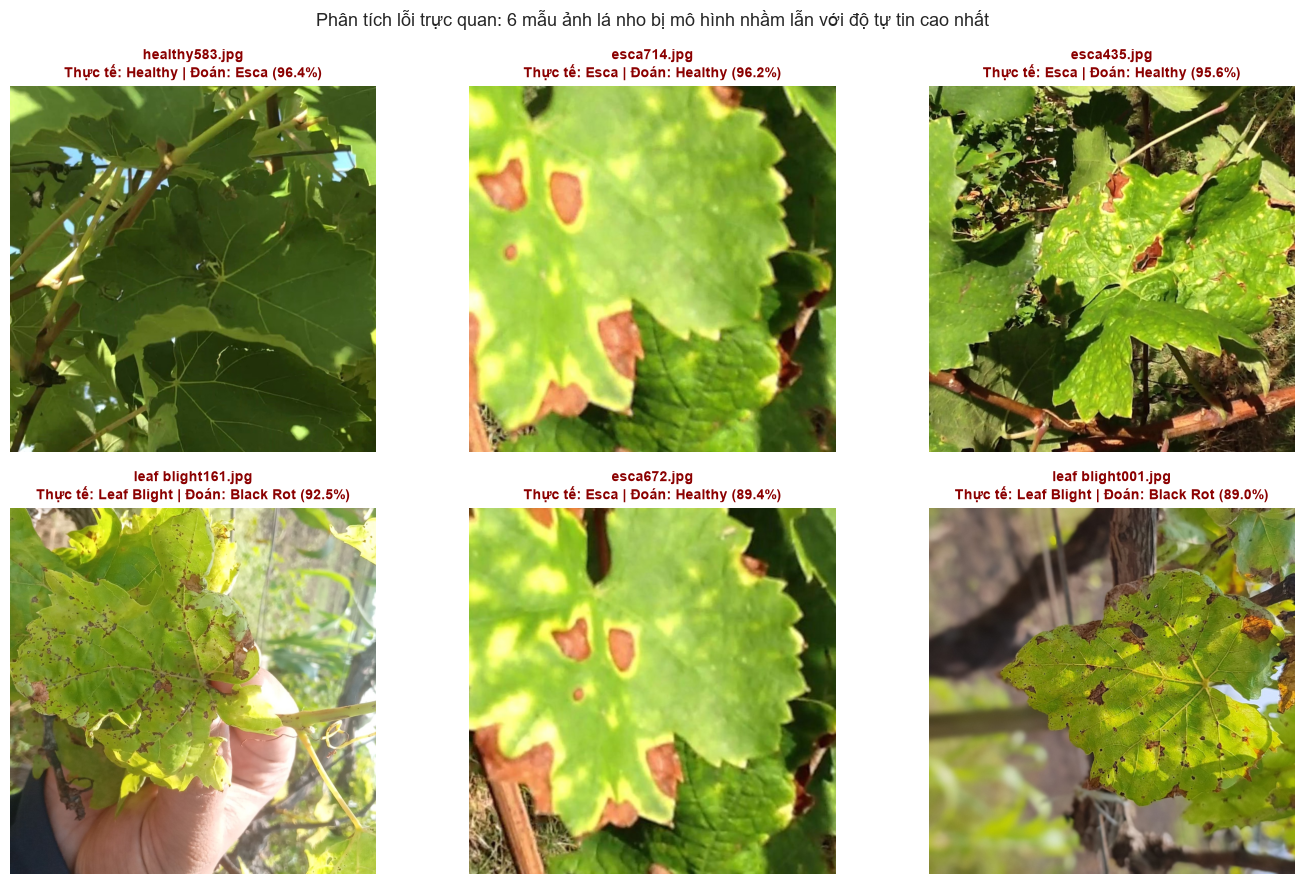

In [16]:
# Trực quan hóa một số bức ảnh bị phân loại nhầm có độ tự tin cao nhất để phân tích nguyên nhân
df_eval_all = df_feat[["Sr_No", "Image_Name", "Image_Path", "Disease_Type", "Split"]].copy()
df_eval_all["Predicted"] = y_oof_best
df_eval_all["Confidence"] = y_oof_prob_best.max(axis=1)
df_errors = df_eval_all[df_eval_all["Disease_Type"] != df_eval_all["Predicted"]].sort_values("Confidence", ascending=False)

print(f"Tổng số ảnh đoán sai trên 5-Fold OOF: {len(df_errors)} / {len(df_eval_all)} ảnh ({len(df_errors)/len(df_eval_all):.2%})")
print("\nThống kê các cặp nhầm lẫn phổ biến nhất (Thực tế -> Dự đoán nhầm):")
pair_counts = (df_errors["Disease_Type"] + "  --->  " + df_errors["Predicted"]).value_counts()
display(pair_counts.rename("So_anh_nham").to_frame().head(8))

if DATASET_DIR.exists() and len(df_errors) > 0:
    sample_err = df_errors.head(6)
    fig, axes = plt.subplots(2, 3, figsize=(14, 9))
    for ax, (_, row) in zip(axes.ravel(), sample_err.iterrows()):
        img_full_path = DATASET_DIR / row["Image_Path"]
        if img_full_path.exists():
            img_bytes = np.fromfile(str(img_full_path), dtype=np.uint8)
            img_bgr = cv2.imdecode(img_bytes, cv2.IMREAD_COLOR)
            img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
            ax.imshow(img_rgb)
        ax.set_title(f"{row['Image_Name']}\nThực tế: {row['Disease_Type']} | Đoán: {row['Predicted']} ({row['Confidence']:.1%})",
                     fontsize=10, color="darkred", fontweight="bold")
        ax.axis("off")
    plt.suptitle("Phân tích lỗi trực quan: 6 mẫu ảnh lá nho bị mô hình nhầm lẫn với độ tự tin cao nhất", fontsize=13)
    plt.tight_layout()
    savefig("bai1_phan_tich_anh_nham_lan")
    plt.show()

#### 📊 Giải thích kết quả: phân tích ảnh bị phân loại nhầm (5-fold OOF)
- **Cell này làm gì:** thống kê các cặp nhầm lẫn của SVM trên toàn bộ dự đoán OOF và hiển thị 6 ảnh bị đoán sai với độ tự tin cao nhất.
- **Số liệu:** 98/2.047 ảnh bị đoán sai (4,79%). **56 trong 98 lỗi (57%) là nhầm giữa Black Rot và Leaf Blight** (30 ảnh Black Rot đoán thành Leaf Blight, 26 ảnh ngược lại). Các cặp còn lại nhỏ hơn nhiều: Leaf Blight → Esca 11, Esca → Healthy 10, Esca → Black Rot 7, Healthy → Esca 6.
- **Quan sát từ 6 ảnh:**
  - `leaf blight161` và `leaf blight001` bị đoán thành Black Rot (89–93%): lá có các đốm nâu nhỏ, đúng kiểu hai bệnh này dễ lẫn nhau khi chỉ dựa vào thống kê màu và kết cấu toàn ảnh.
  - `esca714`, `esca672`, `esca435` bị đoán thành **Healthy** với độ tự tin 89–96%: ảnh có vết nâu viền vàng rất rõ nhưng **chiếm phần nhỏ so với toàn khung hình**, phần còn lại xanh đồng nhất nên thống kê toàn ảnh giống lá khỏe. Đây là hạn chế của đặc trưng toàn cục, mạng CNN (mục 9) có khả năng nhìn vùng tổn thương cục bộ.
  - `healthy583` bị đoán thành Esca: ảnh tối, nhiều bóng râm.

### 9. Hướng B: Huấn luyện Mô hình Học sâu (Deep Learning - Transfer Learning ResNet18)

#### Giải thích : Vì sao kết hợp Transfer Learning (ResNet18) và ColorJitter?
**Mục đích:**
- Ở các mục trên (Hướng A), ta phân loại bệnh qua **25 đặc trưng trích xuất thủ công**. Tuy nhiên, các đặc trưng thống kê toàn cục trên ảnh có thể bỏ sót các đốm bệnh nhỏ hoặc hình thái không gian phức tạp trên gân lá.
- Ở mục này (Hướng B), ta sử dụng mạng nơ-ron tích chập tiền huấn luyện **ResNet18 (Transfer Learning)** đọc trực tiếp ảnh lá nho kích thước `224x224`.

**2 kỹ thuật thiết kế đặc biệt cho bộ dữ liệu GVLiD:**
1. **Chống học đường tắt bằng `ColorJitter`:** Trong bước tăng cường dữ liệu (`transforms.Compose` cho tập `train`), ta thêm `transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2, hue=0.05)` để làm biến thiên ngẫu nhiên độ sáng và độ tương phản của mọi bức ảnh trong lúc học. Nhờ đó, mạng CNN **không thể dựa vào độ sáng nền để đoán mò lớp `Black Rot`**, mà bắt buộc phải học hình thái vết bệnh thật trên lá.
2. **Xử lý mất cân bằng lớp bằng `CrossEntropyLoss` có trọng số (`Sqrt-Balanced`)**: Truyền vector trọng số lớp căn bậc hai vào hàm mất mát để mạng học tốt cả 2 lớp bệnh hiếm (`Black Rot` và `Leaf Blight`).

*(Lưu ý: Đặt `RUN_DEEP_LEARNING = True` để huấn luyện mạng ResNet18 nếu máy có PyTorch; code tự động nhận diện GPU CUDA hoặc CPU và lưu trọng số tốt nhất vào `outputs/bai1/best_resnet18_gvlid.pt`).*

**Chọn thiết bị (GPU/CPU):** đặt `DEVICE_PREFERENCE` ở đầu cell: `"auto"` (mặc định, tự chọn GPU NVIDIA nhiều VRAM trống nhất, không có thì dùng GPU Mac `mps`, cuối cùng là CPU), `"cuda"` hoặc `"cuda:1"` (chỉ định GPU), `"mps"`, hoặc `"cpu"`. Nếu thiết bị yêu cầu không có, code tự cảnh báo và lùi về thiết bị khả dụng. Trên GPU CUDA, `USE_AMP = True` bật mixed precision (FP16) để chạy nhanh và tiết kiệm VRAM.
*Nếu máy có GPU NVIDIA nhưng log báo "Không phát hiện GPU CUDA", bạn đang cài PyTorch bản CPU; cần cài lại bản có CUDA theo hướng dẫn tại pytorch.org.*


In [17]:
import sys
import torch

print("Python EXE:", sys.executable)
print("Torch:", torch.__version__)
print("Torch location:", torch.__file__)


Python EXE: c:\Users\Khang Nguyen\AppData\Local\Programs\Python\Python313\python.exe
Torch: 2.15.0+cu134
Torch location: c:\Users\Khang Nguyen\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\__init__.py


#### 📊 Giải thích kết quả: kiểm tra môi trường PyTorch
- **Cell này làm gì:** in ra trình thông dịch Python và phiên bản PyTorch đang dùng để chắc chắn notebook chạy đúng môi trường.
- **Kết quả:** Python 3.13, PyTorch `2.15.0+cu134` (bản có CUDA). Mục 9 nhận ra GPU NVIDIA nên huấn luyện được trên GPU.

In [18]:
RUN_DEEP_LEARNING = True      # <- Đổi thành False nếu muốn bỏ qua bước huấn luyện CNN khi chạy nhanh trên CPU
DL_EPOCHS = 10                # Số epoch fine-tune ResNet18 (10 epoch với Transfer Learning hội tụ rất nhanh)
BATCH_SIZE = 32
IMG_SIZE = 224

# ---------------- CHỌN THIẾT BỊ TÍNH TOÁN ----------------
# "auto"   : tự chọn GPU NVIDIA (CUDA) có nhiều VRAM trống nhất; không có thì thử GPU Apple (mps); cuối cùng là CPU
# "cuda"   : bắt buộc dùng GPU NVIDIA đầu tiên (cuda:0)       | "cuda:1" : chọn GPU số 1 (máy nhiều GPU)
# "mps"    : GPU của Mac Apple Silicon                         | "cpu"    : ép chạy bằng CPU
# Nếu thiết bị được yêu cầu không có, code tự cảnh báo và lùi về thiết bị khả dụng, không báo lỗi.
DEVICE_PREFERENCE = "auto"
USE_AMP = True            # Mixed precision (FP16) trên GPU CUDA: nhanh hơn và tốn ít VRAM hơn; tự tắt trên CPU/MPS
NUM_WORKERS = 0           # Windows nên để 0; Linux/Mac có thể đặt 2-4 để nạp ảnh nhanh hơn

dl_metrics_summary = None

if RUN_DEEP_LEARNING and DATASET_DIR.exists():
    try:
        import torch
        import torch.nn as nn
        from torch.utils.data import Dataset, DataLoader
        from torchvision import transforms, models

        def select_device(pref="auto"):
            """Chọn thiết bị theo DEVICE_PREFERENCE, tự lùi về thiết bị khả dụng nếu không có."""
            pref = str(pref).lower().strip()
            has_cuda = torch.cuda.is_available()
            has_mps = hasattr(torch.backends, "mps") and torch.backends.mps.is_available()

            if has_cuda:
                print(f"Phát hiện {torch.cuda.device_count()} GPU CUDA:")
                for i in range(torch.cuda.device_count()):
                    p = torch.cuda.get_device_properties(i)
                    free_gb = torch.cuda.mem_get_info(i)[0] / 1024 ** 3
                    print(f"  [{i}] {p.name} | VRAM {p.total_memory / 1024 ** 3:.1f} GB (trống {free_gb:.1f} GB)")
            else:
                print("Không phát hiện GPU CUDA (cần driver NVIDIA và bản PyTorch có hỗ trợ CUDA).")

            if pref == "cpu":
                return torch.device("cpu")
            if pref.startswith("cuda"):
                if has_cuda:
                    idx = int(pref.split(":")[1]) if ":" in pref else 0
                    if idx >= torch.cuda.device_count():
                        print(f"GPU số {idx} không tồn tại, dùng cuda:0.")
                        idx = 0
                    return torch.device(f"cuda:{idx}")
                print("Yêu cầu CUDA nhưng không khả dụng, lùi về lựa chọn tự động.")
            if pref == "mps":
                if has_mps:
                    return torch.device("mps")
                print("Yêu cầu MPS nhưng không khả dụng, lùi về lựa chọn tự động.")
            # Chế độ auto: ưu tiên GPU CUDA còn nhiều VRAM trống nhất
            if has_cuda:
                best = max(range(torch.cuda.device_count()), key=lambda i: torch.cuda.mem_get_info(i)[0])
                return torch.device(f"cuda:{best}")
            if has_mps:
                return torch.device("mps")
            return torch.device("cpu")

        device = select_device(DEVICE_PREFERENCE)
        use_amp = bool(USE_AMP and device.type == "cuda")
        pin_mem = device.type == "cuda"
        if device.type == "cuda":
            torch.backends.cudnn.benchmark = True
        print(f"Đang khởi tạo huấn luyện Deep Learning (ResNet18) trên thiết bị: {device} | Mixed precision: {use_amp}")

        torch.manual_seed(SEED)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(SEED)

        def autocast_ctx():
            """Bật FP16 autocast trên GPU CUDA; trên thiết bị khác là ngữ cảnh rỗng."""
            if use_amp:
                return torch.autocast(device_type="cuda", dtype=torch.float16)
            from contextlib import nullcontext
            return nullcontext()

        class_to_idx = {c: i for i, c in enumerate(CLASSES)}

        class GrapeLeafDataset(Dataset):
            def __init__(self, df_sub, transform=None):
                self.df = df_sub.reset_index(drop=True)
                self.transform = transform

            def __len__(self):
                return len(self.df)

            def __getitem__(self, idx):
                rel_path = self.df.loc[idx, "Image_Path"]
                label_str = self.df.loc[idx, "Disease_Type"]
                full_path = DATASET_DIR / rel_path
                with Image.open(full_path) as img:
                    img_rgb = img.convert("RGB")
                if self.transform:
                    img_tensor = self.transform(img_rgb)
                return img_tensor, class_to_idx[label_str]

        # Chuẩn hóa theo chuẩn ImageNet cho mô hình Pretrained, kèm ColorJitter chống Shortcut Learning
        imagenet_mean = [0.485, 0.456, 0.406]
        imagenet_std  = [0.229, 0.224, 0.225]

        train_transform = transforms.Compose([
            transforms.Resize((IMG_SIZE, IMG_SIZE)),
            transforms.RandomHorizontalFlip(p=0.5),
            transforms.RandomVerticalFlip(p=0.5),
            transforms.RandomRotation(degrees=20),
            transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2, hue=0.05),
            transforms.ToTensor(),
            transforms.Normalize(mean=imagenet_mean, std=imagenet_std),
        ])

        eval_transform = transforms.Compose([
            transforms.Resize((IMG_SIZE, IMG_SIZE)),
            transforms.ToTensor(),
            transforms.Normalize(mean=imagenet_mean, std=imagenet_std),
        ])

        df_tr_dl = df_feat[df_feat["Split"] == "train"]
        df_va_dl = df_feat[df_feat["Split"] == "val"]
        df_te_dl = df_feat[df_feat["Split"] == "test"]

        train_loader = DataLoader(GrapeLeafDataset(df_tr_dl, train_transform), batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=pin_mem)
        val_loader   = DataLoader(GrapeLeafDataset(df_va_dl, eval_transform), batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=pin_mem)
        test_loader  = DataLoader(GrapeLeafDataset(df_te_dl, eval_transform), batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=pin_mem)

        # Khởi tạo ResNet18 tiền huấn luyện
        try:
            cnn_model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        except Exception as e1:
            try:
                cnn_model = models.resnet18(pretrained=True)
            except Exception as e2:
                print("Không tải được trọng số ImageNet (cần Internet). Dùng ResNet18 khởi tạo ngẫu nhiên:", type(e2).__name__)
                cnn_model = models.resnet18(weights=None)

        in_features = cnn_model.fc.in_features
        cnn_model.fc = nn.Sequential(
            nn.Dropout(p=0.3),
            nn.Linear(in_features, K)
        )
        cnn_model = cnn_model.to(device)

        # Trọng số lớp Sqrt-Balanced đưa vào hàm CrossEntropyLoss
        w_tensor = torch.tensor([WEIGHT_SQRT[c] for c in CLASSES], dtype=torch.float32, device=device)
        criterion = nn.CrossEntropyLoss(weight=w_tensor)
        optimizer = torch.optim.AdamW(cnn_model.parameters(), lr=3e-4, weight_decay=1e-4)
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=DL_EPOCHS)
        try:
            scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
        except (AttributeError, TypeError):        # PyTorch cũ chưa có torch.amp.GradScaler
            scaler = torch.cuda.amp.GradScaler(enabled=use_amp)

        best_val_f1 = -1.0
        best_ckpt_path = OUTPUT_DIR / "best_resnet18_gvlid.pt"
        history = []

        for epoch in range(1, DL_EPOCHS + 1):
            t_ep = time.time()
            cnn_model.train()
            tr_loss = 0.0
            for imgs, labels in train_loader:
                imgs, labels = imgs.to(device, non_blocking=True), labels.to(device, non_blocking=True)
                optimizer.zero_grad(set_to_none=True)
                with autocast_ctx():
                    outputs = cnn_model(imgs)
                    loss = criterion(outputs, labels)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
                tr_loss += loss.item() * imgs.size(0)
            scheduler.step()
            tr_loss /= len(df_tr_dl)

            # Đánh giá trên tập Validation
            cnn_model.eval()
            va_preds, va_targets = [], []
            with torch.no_grad(), autocast_ctx():
                for imgs, labels in val_loader:
                    imgs = imgs.to(device, non_blocking=True)
                    logits = cnn_model(imgs)
                    va_preds.extend(logits.argmax(dim=1).cpu().numpy())
                    va_targets.extend(labels.numpy())

            va_acc = accuracy_score(va_targets, va_preds)
            va_f1  = f1_score(va_targets, va_preds, average="macro", zero_division=0)
            history.append({"Epoch": epoch, "Train_Loss": round(tr_loss, 4), "Val_Acc": round(va_acc, 4), "Val_Macro_F1": round(va_f1, 4)})
            print(f"Epoch {epoch:02d}/{DL_EPOCHS:02d} | Train Loss: {tr_loss:.4f} | Val Acc: {va_acc:.4f} | Val Macro F1: {va_f1:.4f} ({time.time()-t_ep:.1f}s)")

            if va_f1 > best_val_f1:
                best_val_f1 = va_f1
                torch.save(cnn_model.state_dict(), best_ckpt_path)

        # Nạp lại trọng số tốt nhất và đánh giá trên tập Hold-out Test
        cnn_model.load_state_dict(torch.load(best_ckpt_path, map_location=device))
        cnn_model.eval()
        te_preds, te_targets = [], []
        with torch.no_grad(), autocast_ctx():
            for imgs, labels in test_loader:
                imgs = imgs.to(device, non_blocking=True)
                logits = cnn_model(imgs)
                te_preds.extend(logits.argmax(dim=1).cpu().numpy())
                te_targets.extend(labels.numpy())

        te_preds_str = [CLASSES[i] for i in te_preds]
        te_targets_str = [CLASSES[i] for i in te_targets]

        print(f"\n=== KẾT QUẢ MẠNG HỌC SÂU RESNET18 TRÊN TẬP HOLD-OUT TEST (N = {len(te_targets_str)}) ===")
        print(classification_report(te_targets_str, te_preds_str, target_names=CLASSES, digits=4))

        per_cls_dl = f1_score(te_targets_str, te_preds_str, labels=CLASSES, average=None, zero_division=0)
        dl_metrics_summary = {
            "Mo_hinh": "9. ResNet18 (Deep Learning + ColorJitter)",
            "Accuracy_Test": round(accuracy_score(te_targets_str, te_preds_str), 4),
            "Balanced_Acc_Test": round(balanced_accuracy_score(te_targets_str, te_preds_str), 4),
            "Macro_F1_Test": round(f1_score(te_targets_str, te_preds_str, average="macro"), 4),
            "Weighted_F1_Test": round(f1_score(te_targets_str, te_preds_str, average="weighted"), 4),
            "F1_BlackRot": round(per_cls_dl[CLASSES.index("Black Rot")], 4),
            "F1_LeafBlight": round(per_cls_dl[CLASSES.index("Leaf Blight")], 4),
            "F1_Esca": round(per_cls_dl[CLASSES.index("Esca")], 4),
            "F1_Healthy": round(per_cls_dl[CLASSES.index("Healthy")], 4),
        }
        if device.type == "cuda":
            torch.cuda.empty_cache()      # giải phóng VRAM sau khi huấn luyện xong
    except ImportError:
        print("Môi trường hiện tại chưa cài đặt PyTorch/torchvision. Bỏ qua bước huấn luyện CNN.")
else:
    print("Bỏ qua bước huấn luyện Deep Learning (RUN_DEEP_LEARNING=False hoặc không tìm thấy thư mục ảnh gốc).")

Phát hiện 1 GPU CUDA:
  [0] NVIDIA GeForce RTX 5060 Laptop GPU | VRAM 8.0 GB (trống 6.9 GB)
Đang khởi tạo huấn luyện Deep Learning (ResNet18) trên thiết bị: cuda:0 | Mixed precision: True
Epoch 01/10 | Train Loss: 0.3489 | Val Acc: 0.9609 | Val Macro F1: 0.8290 (46.7s)
Epoch 02/10 | Train Loss: 0.1882 | Val Acc: 0.9674 | Val Macro F1: 0.8931 (27.7s)
Epoch 03/10 | Train Loss: 0.1188 | Val Acc: 0.9805 | Val Macro F1: 0.9075 (38.0s)
Epoch 04/10 | Train Loss: 0.0825 | Val Acc: 0.9870 | Val Macro F1: 0.9543 (38.6s)
Epoch 05/10 | Train Loss: 0.0991 | Val Acc: 0.9805 | Val Macro F1: 0.9260 (33.4s)
Epoch 06/10 | Train Loss: 0.0803 | Val Acc: 0.9935 | Val Macro F1: 0.9720 (32.3s)
Epoch 07/10 | Train Loss: 0.0542 | Val Acc: 0.9902 | Val Macro F1: 0.9563 (30.7s)
Epoch 08/10 | Train Loss: 0.0318 | Val Acc: 0.9902 | Val Macro F1: 0.9584 (39.6s)
Epoch 09/10 | Train Loss: 0.0297 | Val Acc: 0.9902 | Val Macro F1: 0.9584 (39.0s)
Epoch 10/10 | Train Loss: 0.0305 | Val Acc: 0.9902 | Val Macro F1: 0.9575 

#### 📊 Giải thích kết quả: huấn luyện ResNet18 và kết quả trên test
- **Cell này làm gì:** fine-tune toàn bộ ResNet18 tiền huấn luyện ImageNet trên ảnh gốc 224×224. Huấn luyện chỉ trên tập `train` (1.432 ảnh), dùng tập `val` để chọn checkpoint tốt nhất theo Macro-F1, rồi đánh giá **một lần** trên `test`. Dùng loss có trọng số căn bậc hai, `ColorJitter`, lật, xoay, AdamW lr 3e-4, lịch học Cosine, 10 epoch.
- **Quá trình huấn luyện:** chạy trên GPU RTX 5060 Laptop với mixed precision, khoảng 28–47 giây mỗi epoch (tổng khoảng 6 phút). Train loss giảm từ 0,349 xuống 0,030. Val accuracy tăng từ 0,961 lên 0,990 (đỉnh 0,9935 ở epoch 6). **Val Macro-F1 dao động** (0,829 → 0,893 → 0,908 → 0,954 → 0,926 → **0,972** → 0,956 → 0,958 → 0,958 → 0,958) vì tập val chỉ có 14 ảnh Black Rot và 23 ảnh Leaf Blight. **Checkpoint được lưu là epoch 6** (Macro-F1 val cao nhất).
- **Kết quả test (308 ảnh):** accuracy **0,9773** (301/308), Macro-F1 **0,9280**.

| Lớp | Precision | Recall | F1 | Số ảnh | Recall (khoảng tin cậy 95%) |
|---|---|---|---|---|---|
| Black Rot | 0,813 | 0,867 | 0,839 | 15 | 13/15, khoảng 0,62–0,96 |
| Esca | 1,000 | 0,981 | 0,991 | 106 | 104/106 |
| Healthy | 0,988 | 1,000 | 0,994 | 164 | 164/164 |
| Leaf Blight | 0,909 | 0,870 | 0,889 | 23 | 20/23, khoảng 0,68–0,96 |

- **7 lỗi trên test:** 3 ảnh Leaf Blight đoán thành Black Rot, 2 ảnh Black Rot đoán thành Leaf Blight, 2 ảnh Esca đoán thành Healthy. Như vậy **5/7 lỗi vẫn là nhầm giữa Black Rot và Leaf Blight**, cặp khó nhất cũng với đặc trưng thủ công.
- **So với SVM trên test:** Macro-F1 0,928 so với 0,859 (+0,07), F1 Black Rot 0,839 so với 0,690, F1 Leaf Blight 0,889 so với 0,783. CNN cải thiện chủ yếu ở hai lớp hiếm.

### 10. Tổng hợp kết quả trên tập Test & Xuất báo cáo Bài 1

#### 📝 Giải thích cell: Bảng đối chiếu tổng kết trên tập Hold-out Test & Lưu file kết quả
**Mục đích:**
- Đánh giá đồng loạt tất cả các mô hình Học máy cổ điển (được huấn luyện trên `train + val`) trên cùng một tập **Hold-out Test (`Split == 'test'`)** và đặt cạnh kết quả của mạng **ResNet18** (nếu chạy) để có bảng so sánh toàn diện nhất đưa vào Báo cáo đồ án.
- Xuất toàn bộ các bảng kết quả (`CSV`) và cấu hình tổng kết (`JSON`) vào thư mục `outputs/bai1`.

In [19]:
test_comparison_rows = []
for name, model in get_models(class_weight_mode="sqrt").items():
    model.fit(X_trainval, y_trainval)
    preds_te = model.predict(X_test)
    per_cls = f1_score(y_test, preds_te, labels=CLASSES, average=None, zero_division=0)
    test_comparison_rows.append({
        "Mo_hinh": name,
        "Macro_F1_Test": round(f1_score(y_test, preds_te, average="macro", zero_division=0), 4),
        "Balanced_Acc_Test": round(balanced_accuracy_score(y_test, preds_te), 4),
        "Accuracy_Test": round(accuracy_score(y_test, preds_te), 4),
        "Weighted_F1_Test": round(f1_score(y_test, preds_te, average="weighted", zero_division=0), 4),
        "F1_BlackRot": round(per_cls[CLASSES.index("Black Rot")], 4),
        "F1_LeafBlight": round(per_cls[CLASSES.index("Leaf Blight")], 4),
        "F1_Esca": round(per_cls[CLASSES.index("Esca")], 4),
        "F1_Healthy": round(per_cls[CLASSES.index("Healthy")], 4),
    })

if dl_metrics_summary is not None:
    test_comparison_rows.append(dl_metrics_summary)

df_test_summary = pd.DataFrame(test_comparison_rows).sort_values("Macro_F1_Test", ascending=False).reset_index(drop=True)
print("=== BẢNG TỔNG HỢP HIỆU NĂNG CÁC MÔ HÌNH TRÊN TẬP HOLD-OUT TEST ===")
display(df_test_summary)

# Lưu các bảng kết quả ra CSV phục vụ làm báo cáo
df_feat_rank.to_csv(OUTPUT_DIR / "bai1_xep_hang_dac_trung_kruskal.csv", index=False, encoding="utf-8-sig")
df_cv_results.to_csv(OUTPUT_DIR / "bai1_ket_qua_5fold_cv.csv", index=False, encoding="utf-8-sig")
df_weight_comp.to_csv(OUTPUT_DIR / "bai1_so_sanh_class_weights.csv", index=False, encoding="utf-8-sig")
df_ablation.to_csv(OUTPUT_DIR / "bai1_ablation_study_nhom_dac_trung.csv", index=False, encoding="utf-8-sig")
df_shortcut.to_csv(OUTPUT_DIR / "bai1_kiem_toan_shortcut_learning.csv", index=False, encoding="utf-8-sig")
df_test_summary.to_csv(OUTPUT_DIR / "bai1_ket_qua_holdout_test.csv", index=False, encoding="utf-8-sig")

print("\nĐã lưu toàn bộ bảng biểu và hình ảnh kết quả Bài 1 tại:", OUTPUT_DIR)
for p in sorted(OUTPUT_DIR.iterdir()):
    print(f" - {p.name} ({p.stat().st_size / 1024:.1f} KB)")

=== BẢNG TỔNG HỢP HIỆU NĂNG CÁC MÔ HÌNH TRÊN TẬP HOLD-OUT TEST ===


,Mo_hinh,Macro_F1_Test,Balanced_Acc_Test,Accuracy_Test,Weighted_F1_Test,F1_BlackRot,F1_LeafBlight,F1_Esca,F1_Healthy
0,9. ResNet18 (Deep Learning + ColorJitter),0.9280,0.9293,0.9773,0.9773,0.8387,0.8889,0.9905,0.9939
1,"3. SVM (RBF Kernel, C=3)",0.8591,0.8546,0.9545,0.9541,0.6897,0.7826,0.9765,0.9878
2,"2. KNN (k=7, Distance)",0.8522,0.8416,0.9416,0.9403,0.7333,0.7442,0.9524,0.9790
3,8. MLP (Neural Net 128x64),0.8474,0.8398,0.9448,0.9440,0.6897,0.7556,0.9626,0.9817
4,6. Extra Trees (300 cây),0.8143,0.7929,0.9351,0.9319,0.6429,0.6829,0.9498,0.9817
5,7. HistGradientBoosting,0.7885,0.7747,0.9286,0.9260,0.5714,0.6512,0.9498,0.9816
6,1. Logistic Regression,0.7786,0.7830,0.9188,0.9195,0.5333,0.6667,0.9327,0.9818
7,5. Random Forest (300 cây),0.7763,0.7565,0.9221,0.9183,0.5385,0.6512,0.9369,0.9785
8,4. Decision Tree,0.6894,0.6997,0.8831,0.8793,0.4865,0.4000,0.9050,0.9659
9,0. Dummy (Đoán lớp đa số),0.1737,0.2500,0.5325,0.3700,0.0000,0.0000,0.0000,0.6949



Đã lưu toàn bộ bảng biểu và hình ảnh kết quả Bài 1 tại: D:\DataMining26\Smart-Vineyard\outputs\bai1
 - bai1_ablation_study_nhom_dac_trung.csv (0.7 KB)
 - bai1_ablation_study_va_feature_importance.png (138.7 KB)
 - bai1_boxplot_top6_dac_trung.png (167.6 KB)
 - bai1_confusion_matrix_test_va_oof.png (143.0 KB)
 - bai1_heatmap_tuong_quan_dac_trung.png (206.2 KB)
 - bai1_ket_qua_5fold_cv.csv (1.0 KB)
 - bai1_ket_qua_holdout_test.csv (0.9 KB)
 - bai1_khong_gian_pca_tsne_2d.png (802.7 KB)
 - bai1_kiem_toan_shortcut_learning.csv (0.4 KB)
 - bai1_phan_tich_anh_nham_lan.png (3003.6 KB)
 - bai1_roc_va_pr_curves.png (147.4 KB)
 - bai1_so_sanh_class_weights.csv (0.8 KB)
 - bai1_so_sanh_mo_hinh_5fold_cv.png (76.5 KB)
 - bai1_top15_dac_trung_epsilon2.png (102.3 KB)
 - bai1_xep_hang_dac_trung_kruskal.csv (3.1 KB)
 - best_resnet18_gvlid.pt (43745.2 KB)
 - ml_models (0.0 KB)


#### 📊 Giải thích kết quả: bảng tổng hợp trên tập test và các file đã lưu
- **Cell này làm gì:** huấn luyện lại tất cả mô hình cổ điển trên train + val, đánh giá cùng một tập test với ResNet18 và lưu các bảng kết quả ra CSV.
- **Xếp hạng Macro-F1 trên test:** ResNet18 **0,928**, SVM 0,859, KNN 0,852, MLP 0,847, Extra Trees 0,814, HistGradientBoosting 0,789, Logistic Regression 0,779, Random Forest 0,776, Decision Tree 0,689, Dummy 0,174. Với ResNet18, kết quả ở lần chạy này (0,928) thấp hơn lần chạy trước (0,973), xem ghi chú ở mục 9.
- **Thứ hạng giữa các mô hình cổ điển khác với 5-fold:** Logistic Regression từ hạng 2 (CV) xuống hạng 7 (test), KNN từ hạng 6 lên hạng 2. Vì test có 15 ảnh Black Rot và 23 ảnh Leaf Blight, **không nên diễn giải thứ hạng giữa các mô hình cổ điển trên test**; thứ hạng theo 5-fold đáng tin hơn. Điểm chắc chắn là mọi mô hình cổ điển ở mức 0,69–0,86, và ResNet18 vượt nhóm này ở cả hai lần chạy.
- **Đã lưu** vào `outputs/bai1`: các bảng CSV (xếp hạng đặc trưng, kết quả 5-fold, so sánh trọng số, ablation, kiểm toán độ sáng, kết quả test), các hình biểu đồ, trọng số mạng `best_resnet18_gvlid.pt` (khoảng 43,7 MB) và thư mục `ml_models` (mục 8.1, 8.2).

### 11. Tổng kết & Luận điểm chính đưa vào Báo cáo Đồ án (Bài toán 1)

> Phần này đã được viết lại theo **số liệu thực tế** ở các mục trên. Các nhận định chưa có số liệu hỗ trợ được ghi rõ là giả thuyết hoặc việc cần kiểm chứng.

#### 11.1. Kết quả chính

| Mô hình | Cách đánh giá | Macro-F1 | Balanced Acc. | F1 Black Rot | F1 Leaf Blight |
|---|---|---|---|---|---|
| SVM RBF (25 đặc trưng thủ công) | 5-fold CV | 0,844 ± 0,029 | 0,843 | 0,656 | 0,760 |
| SVM RBF (25 đặc trưng thủ công) | Test (308 ảnh) | 0,859 | 0,855 | 0,690 | 0,783 |
| ResNet18 + ColorJitter (lần chạy trong notebook) | Test (308 ảnh) | **0,928** | 0,929 | **0,839** | **0,889** |
| Đoán lớp đa số (mốc) | 5-fold CV | 0,174 | 0,250 | 0 | 0 |

- ResNet18 vượt SVM khoảng **+0,07 Macro-F1** trên test, chủ yếu nhờ hai lớp hiếm. Trên test, ResNet18 sai 7/308 ảnh (5 lỗi là nhầm giữa Black Rot và Leaf Blight, 2 lỗi Esca đoán thành Healthy).
- **Kết quả ResNet18 không ổn định giữa các lần chạy:** ở lần chạy trước của cùng notebook, Macro-F1 là 0,973 (accuracy 0,9935), lần này là 0,928 (accuracy 0,9773). Nên báo cáo **khoảng 0,93–0,97** hoặc trung bình ± độ lệch chuẩn qua nhiều seed, không báo một con số duy nhất. Trong cả hai lần chạy, ResNet18 đều tốt hơn SVM.
- **Cỡ mẫu nhỏ:** test chỉ có 15 ảnh Black Rot và 23 ảnh Leaf Blight. Recall của ResNet18 ở lần chạy này: Black Rot 13/15 (khoảng tin cậy 95%: 0,62–0,96), Leaf Blight 20/23 (0,68–0,96).
- **Triển khai:** SVM đã được đóng gói (`best_traditional_ml.joblib` kèm script `predict_ml.py`) và ResNet18 có hàm `predict_grape_leaf` để dự đoán ảnh mới. Mới thử trên **một** ảnh nên chưa có ước lượng độ chính xác trên ảnh bên ngoài.

#### 11.2. Vai trò của khử trùng ảnh và mất cân bằng lớp
- Sau khi khử trùng (MD5 + dHash), dữ liệu thật còn **2.047 ảnh độc lập**, mất cân bằng nặng: Healthy 53,3%, Esca 34,5%, Leaf Blight 7,4%, Black Rot 4,7% (96 ảnh). Vì vậy chỉ số chính là **Macro-F1 và Balanced Accuracy** (accuracy bị Healthy chi phối: mô hình đoán toàn bộ là Healthy vẫn đạt 53,4%), kết hợp **5-fold CV**.
- Giả thuyết "khử trùng làm giảm điểm số ảo của Black Rot và Leaf Blight" là hợp lý (ảnh bản sao lọt cả vào train và test), nhưng **notebook này chưa có thí nghiệm đối chứng** trên dữ liệu chưa khử trùng nên chưa có số liệu định lượng. Muốn đưa con số cụ thể vào báo cáo cần chạy thêm thí nghiệm đó.
- **Trọng số lớp:** ảnh hưởng đến Macro-F1 rất nhỏ (chênh tối đa khoảng 0,02, nhỏ hơn độ lệch chuẩn giữa các fold). Trọng số chỉ tăng recall của Black Rot ở SVM (0,615 → 0,656 → 0,677) và Random Forest (0,500 → 0,573 → 0,604), không giúp HistGradientBoosting. `Sqrt` không vượt trội so với `Balanced`.

#### 11.3. Vai trò của các nhóm đặc trưng
- **Màu sắc (HSV) là nhóm mạnh nhất** (Macro-F1 0,812). **Màu + Kết cấu (21 cột) cho kết quả tốt nhất (0,856).** Thêm Hu Moments không cải thiện (0,844, trong phạm vi dao động giữa các fold). Hình dạng một mình chỉ đạt 0,377.
- `HuMoment_1` tương quan khoảng −0,9 với `HSV_V_skew`, nghĩa là Hu Moments (tính trên mặt nạ Otsu của ảnh xám) chủ yếu mang thông tin về phân bố độ sáng. **Nên bỏ nhóm Hu Moments** khỏi bộ đặc trưng cuối.
- Đặc trưng quan trọng nhất: `HSV_S_std`, `HSV_H_mean`, `HSV_H_std`, `GLCM_dissimilarity_std`, `HSV_V_std`.

### 12. Kiểm thử mô hình trên ảnh bên ngoài (External Image Inference)

**Mục tiêu:** Sử dụng checkpoint ResNet18 tốt nhất đã huấn luyện để dự đoán ảnh lá nho mới, không thuộc tập Train/Validation/Test.

**Lưu ý:**
- Chạy sau khi mục 9 đã huấn luyện và lưu `outputs/bai1/best_resnet18_gvlid.pt`.
- Ảnh đầu vào chỉ được tiền xử lý bằng Resize và Normalize; không áp dụng augmentation khi suy luận.
- Thứ tự lớp phải khớp `CLASSES = sorted(df_feat["Disease_Type"].unique())`.
- Confidence là xác suất softmax của mô hình, không phải xác suất mô hình chắc chắn đúng.
- Ảnh bên ngoài chỉ dùng để kiểm thử định tính nếu chưa có nhãn được xác minh; không gộp vào Hold-out Test để báo cáo Accuracy.

In [20]:
from pathlib import Path
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from PIL import Image
from torchvision import models, transforms

# Giữ đúng thứ tự lớp đã dùng khi huấn luyện: sorted(...)
INFERENCE_CLASSES = ["Black Rot", "Esca", "Healthy", "Leaf Blight"]

# Đường dẫn checkpoint được lưu ở Mục 9
INFERENCE_CKPT = OUTPUT_DIR / "best_resnet18_gvlid.pt"

# Chọn thiết bị
INFERENCE_DEVICE = device if "device" in globals() else torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Khởi tạo đúng kiến trúc ResNet18 đã huấn luyện
inference_model = models.resnet18(weights=None)
in_features = inference_model.fc.in_features
inference_model.fc = nn.Sequential(
    nn.Dropout(p=0.3),
    nn.Linear(in_features, len(INFERENCE_CLASSES))
)

if not INFERENCE_CKPT.exists():
    raise FileNotFoundError(
        f"Không tìm thấy checkpoint: {INFERENCE_CKPT}\n"
        "Hãy chạy Mục 9 để huấn luyện ResNet18 và lưu checkpoint trước."
    )

# Tương thích nhiều phiên bản PyTorch
try:
    state = torch.load(
        INFERENCE_CKPT, map_location=INFERENCE_DEVICE, weights_only=True
    )
except TypeError:
    state = torch.load(INFERENCE_CKPT, map_location=INFERENCE_DEVICE)

inference_model.load_state_dict(state)
inference_model.to(INFERENCE_DEVICE)
inference_model.eval()

# Tiền xử lý giống tập Validation/Test
inference_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

def predict_grape_leaf(image_path, show_chart=True):
    """
    Dự đoán một ảnh lá nho bên ngoài dataset.

    Parameters
    ----------
    image_path : str hoặc Path
        Đường dẫn đến ảnh JPG/JPEG/PNG.
    show_chart : bool
        Hiển thị ảnh đầu vào và biểu đồ xác suất dự đoán.
    """
    image_path = Path(image_path)
    if not image_path.is_file():
        raise FileNotFoundError(f"Không tìm thấy ảnh: {image_path}")

    with Image.open(image_path) as img:
        image = img.convert("RGB")

    x = inference_transform(image).unsqueeze(0).to(INFERENCE_DEVICE)

    with torch.inference_mode():
        logits = inference_model(x)
        probs = torch.softmax(logits, dim=1)[0].cpu().numpy()

    pred_idx = int(probs.argmax())
    pred_label = INFERENCE_CLASSES[pred_idx]
    confidence = float(probs[pred_idx])

    print(f"Ảnh: {image_path.name}")
    print(f"Dự đoán: {pred_label}")
    print(f"Confidence (Softmax): {confidence:.2%}")
    print("\nXác suất theo lớp:")
    for label, prob in sorted(
        zip(INFERENCE_CLASSES, probs), key=lambda z: z[1], reverse=True
    ):
        print(f"  {label:12s}: {prob:.2%}")

    if show_chart:
        fig, axes = plt.subplots(1, 2, figsize=(12, 4))
        axes[0].imshow(image)
        axes[0].set_title(f"Ảnh đầu vào\nDự đoán: {pred_label} ({confidence:.1%})")
        axes[0].axis("off")

        order = probs.argsort()
        axes[1].barh(
            [INFERENCE_CLASSES[i] for i in order],
            [probs[i] for i in order]
        )
        axes[1].set_xlim(0, 1)
        axes[1].set_xlabel("Softmax score")
        axes[1].set_title("Xác suất dự đoán theo lớp")
        for y_pos, i in enumerate(order):
            axes[1].text(probs[i] + 0.015, y_pos, f"{probs[i]:.1%}", va="center")

        plt.tight_layout()
        plt.show()

    return {
        "image": str(image_path),
        "predicted_class": pred_label,
        "confidence": confidence,
        "probabilities": dict(zip(INFERENCE_CLASSES, map(float, probs)))
    }

print(f"Đã nạp ResNet18 từ: {INFERENCE_CKPT}")
print(f"Thiết bị suy luận: {INFERENCE_DEVICE}")
print("Sẵn sàng nhận ảnh mới.")


Đã nạp ResNet18 từ: D:\DataMining26\Smart-Vineyard\outputs\bai1\best_resnet18_gvlid.pt
Thiết bị suy luận: cuda:0
Sẵn sàng nhận ảnh mới.


#### 📊 Giải thích kết quả: nạp ResNet18 để dự đoán ảnh mới
- **Cell này làm gì:** dựng lại đúng kiến trúc ResNet18 (Dropout 0,3 + lớp tuyến tính 4 lớp), nạp checkpoint `best_resnet18_gvlid.pt` và định nghĩa hàm `predict_grape_leaf(đường_dẫn_ảnh)`. Hàm resize về 224×224, chuẩn hóa theo ImageNet (không dùng augmentation), tính softmax và vẽ ảnh kèm biểu đồ xác suất.
- **Kết quả:** nạp thành công checkpoint, chạy trên `cuda:0`, sẵn sàng nhận ảnh mới.
- **Lưu ý:** checkpoint bị ghi đè mỗi khi chạy lại mục 9, nên dự đoán ảnh mới luôn dùng **lần huấn luyện gần nhất**. Thứ tự lớp trong `INFERENCE_CLASSES` phải khớp `sorted(...)` lúc huấn luyện.

#### Cách sử dụng

Đặt ảnh mới vào một thư mục, ví dụ `test_images/leaf_external.jpg`, sau đó chạy:

```python
result = predict_grape_leaf("test_images/leaf_external.jpg")
```

Có thể kiểm tra nhiều ảnh lần lượt:

```python
image_paths = [
    "test_images/leaf_01.jpg",
    "test_images/leaf_02.jpg",
    "test_images/leaf_03.jpg",
]

results = [predict_grape_leaf(p, show_chart=False) for p in image_paths]
```

**Diễn giải:** Nếu mô hình dự đoán một lớp với Softmax score cao, đó chỉ là mức độ tự tin tương đối của mô hình trên 4 lớp đã học. Nếu ảnh không phải lá nho hoặc thuộc bệnh ngoài 4 lớp, mô hình vẫn buộc chọn một trong 4 lớp; vì vậy không được xem kết quả này là chẩn đoán chuyên môn.

Ảnh: Black_rot_17.jpg
Dự đoán: Black Rot
Confidence (Softmax): 93.89%

Xác suất theo lớp:
  Black Rot   : 93.89%
  Leaf Blight : 4.53%
  Healthy     : 1.44%
  Esca        : 0.15%


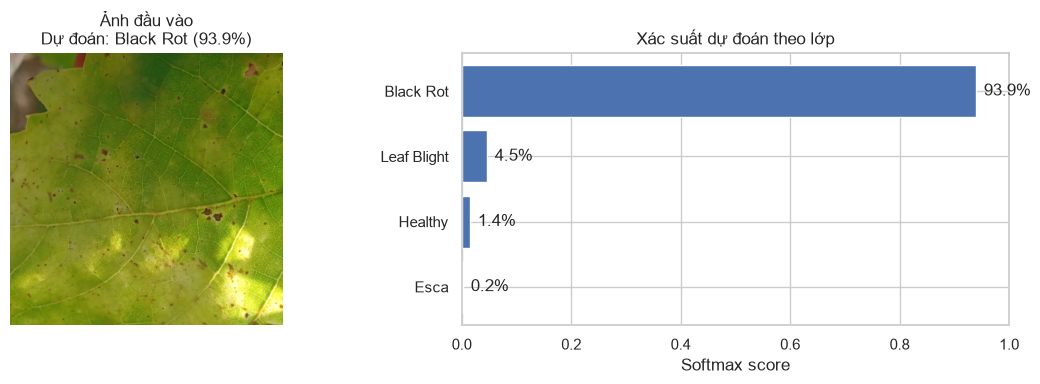

In [28]:
result = predict_grape_leaf(r"D:\DataMining26\Smart-Vineyard\test_images\Black_rot\Black_rot_17.jpg")

#### 📊 Giải thích kết quả: dự đoán thử một ảnh bên ngoài
- **Cell này làm gì:** chạy `predict_grape_leaf` trên ảnh `Black_rot_17.jpg` trong thư mục `test_images`.
- **Kết quả:** dự đoán **Black Rot** với softmax **93,89%**. Các lớp còn lại: Leaf Blight 4,53%, Healthy 1,44%, Esca 0,15%. Ảnh là lá vàng xanh có nhiều đốm nâu nhỏ; khả năng xếp thứ hai là Leaf Blight, đúng cặp lớp hay bị nhầm lẫn với nhau ở các mục trước.
- **Cách đọc đúng:**
  - Đây là **một ảnh duy nhất**, chỉ có giá trị minh họa, **không phải** ước lượng độ chính xác.
  - Softmax 93,9% là mức tự tin của mô hình, không phải xác suất dự đoán đúng; mô hình luôn buộc phải chọn một trong 4 lớp, kể cả khi ảnh không phải lá nho hay là bệnh khác.
  - Cần ghi rõ **nguồn ảnh**. Nếu ảnh lấy từ chính bộ GVLiD (cùng điều kiện chụp) thì chưa phải kiểm tra "bên ngoài" thật sự. Để kiểm tra khả năng tổng quát hóa cần nhiều ảnh từ nguồn khác (máy ảnh, vườn, mùa khác) có nhãn được xác minh.